# Saneamento básico e mortalidade infantil nos municípios brasileiros
### Global Solution — CitizenTech | Disciplina MLAM | Análise estatística em Python

**Integrante**

- Felipe Macedo — RM 570990 (trabalho individual)

---

## Problema e objetivo

**Problema (CitizenTech — cidades, campo e comunidades):** a mortalidade infantil é um dos indicadores mais sensíveis das condições de vida de uma comunidade. No Brasil ela é muito desigual: há municípios com menos de 10 óbitos por mil nascidos vivos e outros com mais de 40. Um gestor público (ou uma solução de tecnologia cívica) precisa saber **onde agir primeiro e sobre quais fatores**.

**Pergunta de análise:** quanto da diferença de mortalidade infantil entre os municípios está associada ao **saneamento básico** (banheiro e água encanada), à **educação** (analfabetismo adulto) e à **renda**? É possível **classificar** os municípios que estão acima da meta de mortalidade infantil usando apenas esses indicadores?

**Base de dados (real):** Atlas do Desenvolvimento Humano no Brasil — PNUD, Ipea e FJP, com indicadores calculados a partir do Censo Demográfico 2010 do IBGE para os 5.565 municípios existentes naquele ano. Fonte original: http://www.atlasbrasil.org.br/ (detalhes da coleta e da limpeza em `codigos/00_obter_base_bruta.py`, `codigos/01_preparacao_base.py` e no `README.md`).

**Roteiro deste notebook** (segue a numeração do enunciado):

| Item | Conteúdo |
|---|---|
| 01 | Base de dados: carga, conferência e estatísticas descritivas |
| 02 | Distribuição Normal de Probabilidade |
| 03 | Testes de hipóteses para a média |
| 04 | Análise bivariada e regressão linear simples |
| 05 | Regressão linear múltipla |
| 06 | Regressão logística binária |
| — | Síntese dos resultados (insumo do relatório do item 07) |

## Configuração do ambiente

In [1]:
from pathlib import Path
import json
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

SEMENTE = 42  # semente fixa: garante que amostras e divisões treino/teste sejam reproduzíveis

# Localiza a raiz do repositório (funciona rodando da raiz ou da pasta codigos/)
RAIZ = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
PASTA_FIGURAS = RAIZ / "figuras"
PASTA_RESULTADOS = RAIZ / "resultados"
PASTA_FIGURAS.mkdir(exist_ok=True)
PASTA_RESULTADOS.mkdir(exist_ok=True)

# Identidade visual única para todos os gráficos
TINTA, TINTA2, GRADE, EIXO, FUNDO = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
AZUL, AZUL_CLARO, LARANJA, VERMELHO, NEUTRO = "#2a78d6", "#b7d3f6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": EIXO, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 10, "font.family": "DejaVu Sans",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
# Mapa divergente para correlações: azul (negativa) - cinza neutro (zero) - vermelho (positiva)
MAPA_CORRELACAO = LinearSegmentedColormap.from_list("correlacao", [AZUL, NEUTRO, VERMELHO])
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list("sequencial", ["#eef4fd", "#184f95"])

def br(valor, casas=2, sinal=False):
    """Formata um número no padrão brasileiro: vírgula decimal e ponto de milhar."""
    texto = f"{valor:+,.{casas}f}" if sinal else f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def fmt_p(p, com_sinal=True):
    """Formata um p-valor: '= 0,0034' ou '< 0,0001' (sem o sinal de igual se com_sinal=False)."""
    if p < 0.0001:
        return "< 0,0001"
    return ("= " if com_sinal else "") + br(p, 4)


eixo_br = lambda casas: plt.FuncFormatter(lambda valor, _: br(valor, casas))  # rótulos de eixo com vírgula

pd.set_option("display.float_format", lambda v: br(v, 3))
pd.set_option("display.width", 140)

RESULTADOS = {}  # dicionário com todos os números usados no relatório (item 07)


def salvar_figura(fig, nome):
    """Salva a figura em figuras/ para uso no relatório."""
    fig.savefig(PASTA_FIGURAS / nome)


def interpretar(texto):
    """Imprime a interpretação de um resultado com quebra de linha organizada."""
    print("INTERPRETAÇÃO")
    for paragrafo in texto.strip().split("\n"):
        if paragrafo.strip():
            print(textwrap.fill(paragrafo.strip(), width=108, break_on_hyphens=False))


def forca_correlacao(r):
    """Classificação usual da intensidade da correlação linear."""
    a = abs(r)
    return "fraca" if a < 0.3 else ("moderada" if a < 0.7 else "forte")


print("Raiz do repositório:", RAIZ.name)

Raiz do repositório: gs-mlam-citizentech


---
## 01) Base de dados

A base de análise (`dados/base_municipios_2010.csv`) é gerada pelo script `codigos/01_preparacao_base.py` a partir da base bruta do Atlas. Cada linha é **um município** no Censo 2010.

| Variável | Papel na análise | Descrição |
|---|---|---|
| `mort_infantil` | resposta (Y) | óbitos de menores de 1 ano por mil nascidos vivos |
| `pct_banheiro_agua` | explicativa | % da população em domicílios com banheiro exclusivo e água encanada em pelo menos um cômodo ("saneamento domiciliar") |
| `taxa_analfabetismo` | explicativa | % de analfabetos entre pessoas de 18 anos ou mais |
| `renda_per_capita` | explicativa | renda domiciliar per capita média mensal (R$ de ago/2010) |
| `alta_mortalidade` | resposta binária | 1 se `mort_infantil` > 15,7 (meta ODM para o Brasil), 0 caso contrário |
| `perfil` | estratificação | predominantemente urbano (≥ 80% de população urbana), rural (< 50%) ou intermediário |

In [2]:
df = pd.read_csv(RAIZ / "dados" / "base_municipios_2010.csv")

print(f"Dimensões: {df.shape[0]} municípios x {df.shape[1]} variáveis")
print(f"Valores ausentes: {int(df.isna().sum().sum())} | municípios duplicados: {int(df['cod_municipio'].duplicated().sum())}")
df.head()

Dimensões: 5565 municípios x 13 variáveis
Valores ausentes: 0 | municípios duplicados: 0


,cod_municipio,municipio,uf,nome_uf,regiao,populacao,pct_pop_urbana,perfil,mort_infantil,pct_banheiro_agua,taxa_analfabetismo,renda_per_capita,alta_mortalidade
0,1100015,ALTA FLORESTA D'OESTE,RO,Rondônia,Norte,24392,"57,270",Intermediário,"23,800","80,200","13,000","476,990",1
1,1100023,ARIQUEMES,RO,Rondônia,Norte,90353,"84,700",Predominantemente urbano,"19,200","85,350","8,530","689,950",1
2,1100031,CABIXI,RO,Rondônia,Norte,6313,"42,660",Predominantemente rural,"24,800","91,630","14,730","457,170",1
3,1100049,CACOAL,RO,Rondônia,Norte,78574,"78,810",Intermediário,"14,300","93,440","8,940","738,060",0
4,1100056,CEREJEIRAS,RO,Rondônia,Norte,17029,"84,670",Predominantemente urbano,"18,100","86,870","11,170","577,180",1


In [3]:
VAR_Y = "mort_infantil"
VARS_X = ["pct_banheiro_agua", "taxa_analfabetismo", "renda_per_capita"]
ROTULOS = {
    "mort_infantil": "Mortalidade infantil (por mil)",
    "pct_banheiro_agua": "Banheiro e água encanada (%)",
    "taxa_analfabetismo": "Analfabetismo 18+ (%)",
    "renda_per_capita": "Renda per capita (R$)",
}
META_ODM = 15.7  # meta ODM de mortalidade infantil para o Brasil (óbitos por mil nascidos vivos)

descritivas = df[[VAR_Y] + VARS_X].describe().T
descritivas["mediana"] = df[[VAR_Y] + VARS_X].median()
descritivas["assimetria"] = df[[VAR_Y] + VARS_X].skew()
descritivas["count"] = descritivas["count"].astype(int)
descritivas = descritivas[["count", "mean", "mediana", "std", "min", "max", "assimetria"]]
descritivas.columns = ["n", "média", "mediana", "desvio padrão (amostral)", "mínimo", "máximo", "assimetria"]
RESULTADOS["descritivas"] = descritivas.round(4).to_dict(orient="index")
descritivas

,n,média,mediana,desvio padrão (amostral),mínimo,máximo,assimetria
mort_infantil,5565,"19,247","16,900","7,137","8,490","46,800","1,006"
pct_banheiro_agua,5565,"80,872","91,250","21,712","3,260","100,000","-1,213"
taxa_analfabetismo,5565,"17,405","14,110","10,699","0,970","47,640","0,598"
renda_per_capita,5565,"493,606","467,650","243,269","96,250","2.043,740","0,960"


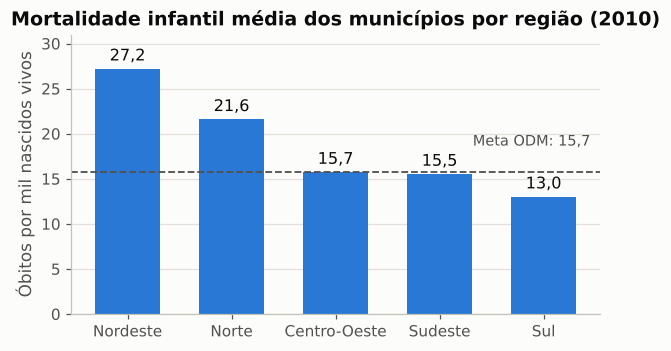

Indicadores médios por região:


,municipios,mort_infantil_media,pct_acima_meta,banheiro_agua_medio,analfabetismo_medio,renda_media
regiao,,,,,,
Nordeste,1794,"27,190","99,050","61,990","29,480","276,920"
Norte,449,"21,580","90,420","56,050","18,710","345,090"
Centro-Oeste,466,"15,730","42,920","91,480","13,160","586,650"
Sudeste,1668,"15,510","43,940","94,520","11,610","590,620"
Sul,1188,"13,000","11,780","95,430","8,470","704,240"


Indicadores médios por perfil urbano/rural:


,municipios,mort_infantil_media,pct_acima_meta,banheiro_agua_medio,analfabetismo_medio,renda_media
perfil,,,,,,
Predominantemente urbano,1599,"15,530","33,960","94,060","10,330","671,260"
Intermediário,2347,"19,840","64,420","81,110","18,580","454,270"
Predominantemente rural,1619,"22,060","74,180","67,510","22,690","375,160"


In [4]:
ORDEM_REGIOES = ["Nordeste", "Norte", "Centro-Oeste", "Sudeste", "Sul"]
por_regiao = (
    df.groupby("regiao")
      .agg(municipios=("municipio", "size"),
           mort_infantil_media=("mort_infantil", "mean"),
           pct_acima_meta=("alta_mortalidade", lambda s: 100 * s.mean()),
           banheiro_agua_medio=("pct_banheiro_agua", "mean"),
           analfabetismo_medio=("taxa_analfabetismo", "mean"),
           renda_media=("renda_per_capita", "mean"))
      .loc[ORDEM_REGIOES]
)
RESULTADOS["por_regiao"] = por_regiao.round(2).to_dict(orient="index")

ORDEM_PERFIS = ["Predominantemente urbano", "Intermediário", "Predominantemente rural"]
por_perfil = (
    df.groupby("perfil")
      .agg(municipios=("municipio", "size"),
           mort_infantil_media=("mort_infantil", "mean"),
           pct_acima_meta=("alta_mortalidade", lambda s: 100 * s.mean()),
           banheiro_agua_medio=("pct_banheiro_agua", "mean"),
           analfabetismo_medio=("taxa_analfabetismo", "mean"),
           renda_media=("renda_per_capita", "mean"))
      .loc[ORDEM_PERFIS]
)
RESULTADOS["por_perfil"] = por_perfil.round(2).to_dict(orient="index")
RESULTADOS["geral"] = {
    "n_municipios": int(len(df)),
    "meta_odm": META_ODM,
    "n_acima_meta": int(df["alta_mortalidade"].sum()),
    "pct_acima_meta": float(100 * df["alta_mortalidade"].mean()),
    "n_urbanos": int((df["perfil"] == "Predominantemente urbano").sum()),
    "n_rurais": int((df["perfil"] == "Predominantemente rural").sum()),
}

fig, ax = plt.subplots(figsize=(6.2, 3.3))
barras = ax.bar(por_regiao.index, por_regiao["mort_infantil_media"], color=AZUL, width=0.62)
ax.bar_label(barras, labels=[br(v, 1) for v in por_regiao["mort_infantil_media"]], padding=3, color=TINTA, fontsize=10.5)
ax.axhline(META_ODM, color=TINTA2, linestyle="--", linewidth=1.2)
ax.text(4.45, META_ODM + 2.6, f"Meta ODM: {br(META_ODM, 1)}", ha="right", va="bottom", color=TINTA2, fontsize=9.5)
ax.set_title("Mortalidade infantil média dos municípios por região (2010)")
ax.set_ylabel("Óbitos por mil nascidos vivos")
ax.set_ylim(0, 31)
ax.grid(axis="x", visible=False)
salvar_figura(fig, "fig01_mortalidade_por_regiao.png")
plt.show()

print("Indicadores médios por região:")
display(por_regiao.round(2))
print("Indicadores médios por perfil urbano/rural:")
display(por_perfil.round(2))

In [5]:
interpretar(f"""
A base tem {len(df)} municípios, sem valores ausentes. A mortalidade infantil média é de {br(df[VAR_Y].mean(), 2)} óbitos por mil nascidos vivos, com mediana de {br(df[VAR_Y].median(), 2)} (assimetria positiva de {br(df[VAR_Y].skew(), 2)}: poucos municípios com valores muito altos puxam a média para cima).
{RESULTADOS['geral']['n_acima_meta']} municípios ({br(RESULTADOS['geral']['pct_acima_meta'], 1)}%) estão acima da meta ODM de {br(META_ODM, 1)} por mil.
A desigualdade regional é grande: a média vai de {br(por_regiao['mort_infantil_media'].min(), 1)} (Sul) a {br(por_regiao['mort_infantil_media'].max(), 1)} (Nordeste), onde {br(por_regiao.loc['Nordeste', 'pct_acima_meta'], 1)}% dos municípios estão acima da meta. As regiões com maior mortalidade são também as de menor cobertura de banheiro e água encanada e maior analfabetismo.
O mesmo vale para o recorte cidade x campo: a mortalidade infantil média é de {br(por_perfil.loc['Predominantemente urbano', 'mort_infantil_media'], 1)} nos municípios predominantemente urbanos e de {br(por_perfil.loc['Predominantemente rural', 'mort_infantil_media'], 1)} nos predominantemente rurais, onde {br(por_perfil.loc['Predominantemente rural', 'pct_acima_meta'], 1)}% estão acima da meta.
""")

INTERPRETAÇÃO
A base tem 5565 municípios, sem valores ausentes. A mortalidade infantil média é de 19,25 óbitos por mil
nascidos vivos, com mediana de 16,90 (assimetria positiva de 1,01: poucos municípios com valores muito altos
puxam a média para cima).
3256 municípios (58,5%) estão acima da meta ODM de 15,7 por mil.
A desigualdade regional é grande: a média vai de 13,0 (Sul) a 27,2 (Nordeste), onde 99,1% dos municípios
estão acima da meta. As regiões com maior mortalidade são também as de menor cobertura de banheiro e água
encanada e maior analfabetismo.
O mesmo vale para o recorte cidade x campo: a mortalidade infantil média é de 15,5 nos municípios
predominantemente urbanos e de 22,1 nos predominantemente rurais, onde 74,2% estão acima da meta.


---
## 02) Distribuição Normal de Probabilidade

**Variável aleatória escolhida:** X = mortalidade infantil do município (óbitos por mil nascidos vivos).

Conforme o enunciado, **assume-se** que X ~ Normal(μ, σ), com μ e σ iguais à média e ao desvio padrão **populacionais** dos registros (a base contém todos os municípios, por isso `ddof=0`).

Escala usada para classificar os eventos pelo resultado probabilístico:

| Probabilidade | Classificação |
|---|---|
| P = 0 | evento impossível |
| 0 < P < 0,5 | evento improvável (menos provável do que o seu complementar) |
| P = 0,5 | evento tão provável quanto improvável |
| 0,5 < P < 1 | evento provável (mais provável do que o seu complementar) |
| P = 1 | evento certo |

In [6]:
def classificar_evento(p, tolerancia=1e-9):
    """Classifica um evento a partir da sua probabilidade."""
    if p <= tolerancia:
        return "evento impossível"
    if p >= 1 - tolerancia:
        return "evento certo"
    if abs(p - 0.5) <= tolerancia:
        return "evento tão provável quanto improvável"
    return "evento provável" if p > 0.5 else "evento improvável"


x = df[VAR_Y]
mu = x.mean()            # média populacional
sigma = x.std(ddof=0)    # desvio padrão populacional
mediana = x.median()

print(f"Média (mu)             = {br(mu, 4)}")
print(f"Desvio padrão (sigma)  = {br(sigma, 4)}")
print(f"Mediana                = {br(mediana, 4)}")

Média (mu)             = 19,2470
Desvio padrão (sigma)  = 7,1360
Mediana                = 16,9000


### a) P(X < média) e classificação do evento

In [7]:
z_a = (mu - mu) / sigma                           # padronização: z = (x - mu) / sigma
p_a = stats.norm.cdf(mu, loc=mu, scale=sigma)     # P(X < mu) = área à esquerda da média
classe_a = classificar_evento(p_a)
prop_empirica_a = (x < mu).mean()

print(f"z = (média - mu) / sigma = {br(z_a, 4)}")
print(f"P(X < {br(mu, 2)}) = {br(p_a, 4)} = {br(100 * p_a, 2)}%")
print(f"Classificação: {classe_a}")
print(f"Proporção observada na base (sem assumir normalidade): {br(100 * prop_empirica_a, 2)}%")

interpretar(f"""
Sob a distribuição Normal, a média divide a curva em duas metades iguais, então P(X < média) = {br(p_a, 2)}: trata-se de um {classe_a}. Em termos práticos, um município sorteado ao acaso tem a mesma chance de estar abaixo ou acima de {br(mu, 2)} óbitos por mil.
Conferência com os dados reais: {br(100 * prop_empirica_a, 1)}% dos municípios estão abaixo da média. A diferença em relação aos 50% do modelo aparece porque a distribuição real é assimétrica à direita; essa é uma limitação da hipótese de normalidade imposta pelo enunciado.
""")

z = (média - mu) / sigma = 0,0000
P(X < 19,25) = 0,5000 = 50,00%
Classificação: evento tão provável quanto improvável
Proporção observada na base (sem assumir normalidade): 61,24%
INTERPRETAÇÃO
Sob a distribuição Normal, a média divide a curva em duas metades iguais, então P(X < média) = 0,50:
trata-se de um evento tão provável quanto improvável. Em termos práticos, um município sorteado ao acaso tem
a mesma chance de estar abaixo ou acima de 19,25 óbitos por mil.
Conferência com os dados reais: 61,2% dos municípios estão abaixo da média. A diferença em relação aos 50%
do modelo aparece porque a distribuição real é assimétrica à direita; essa é uma limitação da hipótese de
normalidade imposta pelo enunciado.


### b) P(X > mediana) e classificação do evento

In [8]:
z_b = (mediana - mu) / sigma
p_b = 1 - stats.norm.cdf(mediana, loc=mu, scale=sigma)   # P(X > mediana) = área à direita da mediana
classe_b = classificar_evento(p_b)
prop_empirica_b = (x > mediana).mean()

print(f"z = (mediana - mu) / sigma = ({br(mediana, 2)} - {br(mu, 4)}) / {br(sigma, 4)} = {br(z_b, 4)}")
print(f"P(X > {br(mediana, 2)}) = 1 - P(Z < {br(z_b, 4)}) = {br(p_b, 4)} = {br(100 * p_b, 2)}%")
print(f"Classificação: {classe_b}")
print(f"Proporção observada na base (sem assumir normalidade): {br(100 * prop_empirica_b, 2)}%")

interpretar(f"""
Como a mediana ({br(mediana, 2)}) é menor do que a média ({br(mu, 2)}), ela fica {br(abs(z_b), 2)} desvio padrão abaixo do centro da curva Normal. Por isso a área à direita dela é maior que a metade: P(X > mediana) = {br(100 * p_b, 2)}%, um {classe_b}.
Conferência com os dados reais: por definição, cerca de metade dos municípios ({br(100 * prop_empirica_b, 1)}%) está acima da mediana. O modelo Normal superestima essa probabilidade em {br(100 * (p_b - prop_empirica_b), 1)} pontos percentuais, novamente por causa da assimetria.
""")

RESULTADOS["item02"] = {
    "mu": float(mu), "sigma": float(sigma), "mediana": float(mediana),
    "z_a": float(z_a), "p_a": float(p_a), "classe_a": classe_a, "prop_empirica_a": float(prop_empirica_a),
    "z_b": float(z_b), "p_b": float(p_b), "classe_b": classe_b, "prop_empirica_b": float(prop_empirica_b),
}

z = (mediana - mu) / sigma = (16,90 - 19,2470) / 7,1360 = -0,3289
P(X > 16,90) = 1 - P(Z < -0,3289) = 0,6289 = 62,89%
Classificação: evento provável
Proporção observada na base (sem assumir normalidade): 49,99%
INTERPRETAÇÃO
Como a mediana (16,90) é menor do que a média (19,25), ela fica 0,33 desvio padrão abaixo do centro da curva
Normal. Por isso a área à direita dela é maior que a metade: P(X > mediana) = 62,89%, um evento provável.
Conferência com os dados reais: por definição, cerca de metade dos municípios (50,0%) está acima da mediana.
O modelo Normal superestima essa probabilidade em 12,9 pontos percentuais, novamente por causa da
assimetria.


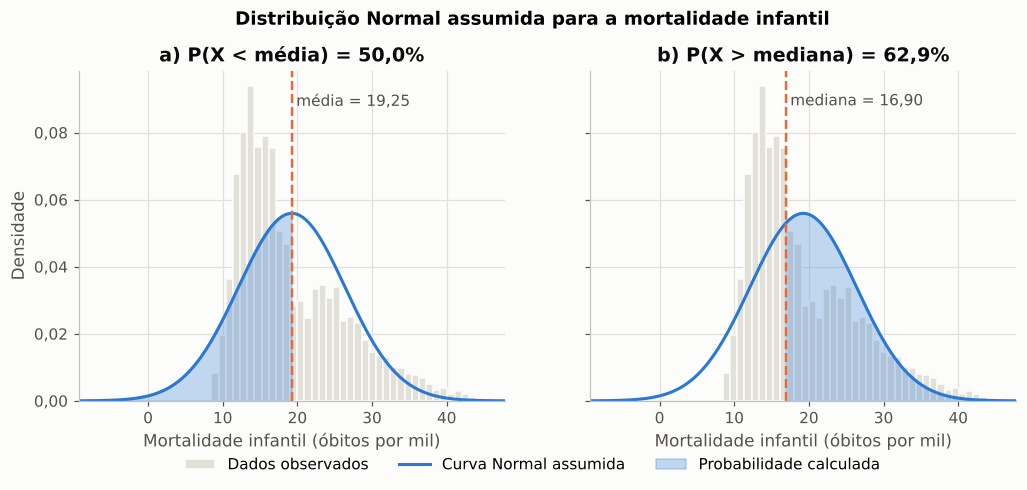

In [9]:
grade = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
densidade = stats.norm.pdf(grade, mu, sigma)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
paineis = [
    (eixos[0], grade <= mu, mu, f"a) P(X < média) = {br(100 * p_a, 1)}%", f"média = {br(mu, 2)}"),
    (eixos[1], grade >= mediana, mediana, f"b) P(X > mediana) = {br(100 * p_b, 1)}%", f"mediana = {br(mediana, 2)}"),
]
for ax, mascara, corte, titulo, rotulo in paineis:
    ax.hist(x, bins=40, density=True, color=GRADE, edgecolor=FUNDO, label="Dados observados")
    ax.plot(grade, densidade, color=AZUL, linewidth=2, label="Curva Normal assumida")
    ax.fill_between(grade, densidade, where=mascara, color=AZUL, alpha=0.28, label="Probabilidade calculada")
    ax.axvline(corte, color=LARANJA, linewidth=1.6, linestyle="--")
    ax.text(corte + 0.6, ax.get_ylim()[1] * 0.93, rotulo, color=TINTA2, fontsize=10, va="top")
    ax.set_title(titulo)
    ax.set_xlabel("Mortalidade infantil (óbitos por mil)")
    ax.set_xlim(mu - 4 * sigma, mu + 4 * sigma)
    ax.yaxis.set_major_formatter(eixo_br(2))
eixos[0].set_ylabel("Densidade")
marcas, nomes = eixos[0].get_legend_handles_labels()
fig.legend(marcas, nomes, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.09))
fig.suptitle("Distribuição Normal assumida para a mortalidade infantil", fontweight="bold", y=1.02)
salvar_figura(fig, "fig02_distribuicao_normal.png")
plt.show()

---
## 03) Testes de hipóteses para a média

**Variável:** mortalidade infantil (assumida Normal). **Referências do problema**, conforme o enunciado:

- média populacional de referência: μ₀ = média de todos os municípios da base;
- desvio padrão de referência: σ = desvio padrão **populacional** dos dados.

Como σ é conhecido e a variável é assumida Normal, a estatística adequada é o **teste Z para a média**:

$$z_{calc} = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}}$$

**Desenho amostral ligado ao problema (cidade x campo):**

- **item a)** amostra aleatória simples de **20** municípios *predominantemente urbanos* (≥ 80% da população em área urbana) — a pergunta é se a média desse grupo é **menor** do que a referência nacional (α = 6%);
- **item b)** amostra aleatória simples de **25** municípios *predominantemente rurais* (< 50% da população em área urbana) — a pergunta é se a média desse grupo é **maior** do que a referência nacional (α = 9%).

As amostras são sorteadas com semente fixa (`SEMENTE = 42`) para que o resultado seja reproduzível.

In [10]:
mu0 = mu                 # média populacional de referência
sigma_ref = sigma        # desvio padrão de referência = desvio padrão populacional dos dados
print(f"Média de referência (mu0)        = {br(mu0, 4)}")
print(f"Desvio padrão de referência      = {br(sigma_ref, 4)}")


def teste_z_media(amostra, mu0, sigma, alfa, cauda):
    """Teste Z unilateral para a média com desvio padrão populacional conhecido.

    cauda = 'esquerda' -> H1: mu < mu0 | cauda = 'direita' -> H1: mu > mu0
    """
    n = len(amostra)
    media_amostral = float(np.mean(amostra))
    erro_padrao = sigma / np.sqrt(n)
    z_calc = (media_amostral - mu0) / erro_padrao
    if cauda == "esquerda":
        z_crit = stats.norm.ppf(alfa)            # região crítica: z < z_crit
        p_valor = stats.norm.cdf(z_calc)
        rejeita = z_calc < z_crit
    else:
        z_crit = stats.norm.ppf(1 - alfa)        # região crítica: z > z_crit
        p_valor = 1 - stats.norm.cdf(z_calc)
        rejeita = z_calc > z_crit
    return {"n": n, "media_amostral": media_amostral, "erro_padrao": float(erro_padrao),
            "z_calc": float(z_calc), "z_crit": float(z_crit), "p_valor": float(p_valor),
            "alfa": alfa, "cauda": cauda, "rejeita_h0": bool(rejeita)}


def proporcao_rejeicoes(valores, n, mu0, sigma, alfa, cauda, repeticoes=10_000, semente=SEMENTE):
    """Repete o sorteio da amostra muitas vezes e mede em que fração delas H0 seria rejeitada."""
    rng = np.random.default_rng(semente)
    rejeicoes = 0
    for _ in range(repeticoes):
        amostra = rng.choice(valores, size=n, replace=False)
        rejeicoes += teste_z_media(amostra, mu0, sigma, alfa, cauda)["rejeita_h0"]
    return rejeicoes / repeticoes

Média de referência (mu0)        = 19,2470
Desvio padrão de referência      = 7,1360


### a) Média amostral menor do que a referência — α = 6%, n = 20

- **H₀:** μ_urbanos = μ₀ (a mortalidade infantil média dos municípios predominantemente urbanos **não é menor** do que a referência nacional)
- **H₁:** μ_urbanos < μ₀ (teste unilateral **à esquerda**)

In [11]:
urbanos = df[df["perfil"] == "Predominantemente urbano"]
amostra_a = urbanos.sample(n=20, random_state=SEMENTE)
teste_a = teste_z_media(amostra_a[VAR_Y].to_numpy(), mu0, sigma_ref, alfa=0.06, cauda="esquerda")

print("Municípios sorteados:", ", ".join(f"{m} ({u})" for m, u in zip(amostra_a["municipio"], amostra_a["uf"])))
print()
print(f"n = {teste_a['n']} | média amostral = {br(teste_a['media_amostral'], 4)} | mu0 = {br(mu0, 4)}")
print(f"Erro padrão = sigma / raiz(n) = {br(sigma_ref, 4)} / raiz({teste_a['n']}) = {br(teste_a['erro_padrao'], 4)}")
print(f"z calculado = ({br(teste_a['media_amostral'], 4)} - {br(mu0, 4)}) / {br(teste_a['erro_padrao'], 4)} = {br(teste_a['z_calc'], 4)}")
print(f"z crítico (alfa = 6%, cauda esquerda) = {br(teste_a['z_crit'], 4)}")
print(f"p-valor {fmt_p(teste_a['p_valor'])}")
print("Decisão:", "REJEITA-SE H0" if teste_a["rejeita_h0"] else "NÃO se rejeita H0")

teste_a["media_real_grupo"] = float(urbanos[VAR_Y].mean())
teste_a["n_grupo"] = int(len(urbanos))
teste_a["prop_rejeicoes"] = proporcao_rejeicoes(urbanos[VAR_Y].to_numpy(), 20, mu0, sigma_ref, 0.06, "esquerda")

interpretar(f"""
A média da amostra ({br(teste_a['media_amostral'], 2)}) ficou abaixo da referência ({br(mu0, 2)}). Como z calculado ({br(teste_a['z_calc'], 2)}) {'é menor' if teste_a['rejeita_h0'] else 'não é menor'} que o z crítico ({br(teste_a['z_crit'], 2)}) e o p-valor ({fmt_p(teste_a['p_valor'], com_sinal=False)}) {'é menor' if teste_a['p_valor'] < 0.06 else 'é maior'} que alfa = 0,06, {'rejeita-se H0: há evidência estatística, ao nível de 6%, de que a mortalidade infantil média dos municípios predominantemente urbanos é menor do que a referência nacional' if teste_a['rejeita_h0'] else 'não se rejeita H0: a amostra não traz evidência suficiente, ao nível de 6%, de que a média dos municípios predominantemente urbanos seja menor do que a referência nacional'}.
Robustez: repetindo o sorteio 10.000 vezes, H0 seria rejeitada em {br(100 * teste_a['prop_rejeicoes'], 1)}% das amostras de tamanho 20. A decisão se repete, portanto, na grande maioria dos sorteios possíveis, mas não em todos: com apenas 20 municípios ainda há {br(100 * (1 - teste_a['prop_rejeicoes']), 1)}% de chance de não detectar a diferença. A média real do grupo (todos os {teste_a['n_grupo']} municípios urbanos) é {br(teste_a['media_real_grupo'], 2)}, coerente com a decisão do teste.
""")

Municípios sorteados: INDAIATUBA (SP), MOSSORÓ (RN), CENTRALINA (MG), BIRIGUI (SP), CAPIVARI DO SUL (RS), REGENTE FEIJÓ (SP), ALOÂNDIA (GO), CAIEIRAS (SP), PARACAMBI (RJ), SENADOR CANEDO (GO), SANTA RITA DO SAPUCAÍ (MG), BOM JESUS DE GOIÁS (GO), FORMOSA (GO), PORTEIRÃO (GO), PILAR (AL), SANTANA DE PARNAÍBA (SP), VITÓRIA DO JARI (AP), PIRACICABA (SP), PIRAÚBA (MG), SÃO JOSÉ DO CAMPESTRE (RN)

n = 20 | média amostral = 14,9335 | mu0 = 19,2470
Erro padrão = sigma / raiz(n) = 7,1360 / raiz(20) = 1,5957
z calculado = (14,9335 - 19,2470) / 1,5957 = -2,7033
z crítico (alfa = 6%, cauda esquerda) = -1,5548
p-valor = 0,0034
Decisão: REJEITA-SE H0


INTERPRETAÇÃO
A média da amostra (14,93) ficou abaixo da referência (19,25). Como z calculado (-2,70) é menor que o z
crítico (-1,55) e o p-valor (0,0034) é menor que alfa = 0,06, rejeita-se H0: há evidência estatística, ao
nível de 6%, de que a mortalidade infantil média dos municípios predominantemente urbanos é menor do que a
referência nacional.
Robustez: repetindo o sorteio 10.000 vezes, H0 seria rejeitada em 86,3% das amostras de tamanho 20. A
decisão se repete, portanto, na grande maioria dos sorteios possíveis, mas não em todos: com apenas 20
municípios ainda há 13,7% de chance de não detectar a diferença. A média real do grupo (todos os 1599
municípios urbanos) é 15,53, coerente com a decisão do teste.


### b) Média amostral maior do que a referência — α = 9%, n = 25

- **H₀:** μ_rurais = μ₀ (a mortalidade infantil média dos municípios predominantemente rurais **não é maior** do que a referência nacional)
- **H₁:** μ_rurais > μ₀ (teste unilateral **à direita**)

In [12]:
rurais = df[df["perfil"] == "Predominantemente rural"]
amostra_b = rurais.sample(n=25, random_state=SEMENTE)
teste_b = teste_z_media(amostra_b[VAR_Y].to_numpy(), mu0, sigma_ref, alfa=0.09, cauda="direita")

print("Municípios sorteados:", ", ".join(f"{m} ({u})" for m, u in zip(amostra_b["municipio"], amostra_b["uf"])))
print()
print(f"n = {teste_b['n']} | média amostral = {br(teste_b['media_amostral'], 4)} | mu0 = {br(mu0, 4)}")
print(f"Erro padrão = sigma / raiz(n) = {br(sigma_ref, 4)} / raiz({teste_b['n']}) = {br(teste_b['erro_padrao'], 4)}")
print(f"z calculado = ({br(teste_b['media_amostral'], 4)} - {br(mu0, 4)}) / {br(teste_b['erro_padrao'], 4)} = {br(teste_b['z_calc'], 4)}")
print(f"z crítico (alfa = 9%, cauda direita) = {br(teste_b['z_crit'], 4)}")
print(f"p-valor {fmt_p(teste_b['p_valor'])}")
print("Decisão:", "REJEITA-SE H0" if teste_b["rejeita_h0"] else "NÃO se rejeita H0")

teste_b["media_real_grupo"] = float(rurais[VAR_Y].mean())
teste_b["n_grupo"] = int(len(rurais))
teste_b["prop_rejeicoes"] = proporcao_rejeicoes(rurais[VAR_Y].to_numpy(), 25, mu0, sigma_ref, 0.09, "direita")

interpretar(f"""
A média da amostra ({br(teste_b['media_amostral'], 2)}) ficou acima da referência ({br(mu0, 2)}). Como z calculado ({br(teste_b['z_calc'], 2)}) {'é maior' if teste_b['rejeita_h0'] else 'não é maior'} que o z crítico ({br(teste_b['z_crit'], 2)}) e o p-valor ({fmt_p(teste_b['p_valor'], com_sinal=False)}) {'é menor' if teste_b['p_valor'] < 0.09 else 'é maior'} que alfa = 0,09, {'rejeita-se H0: há evidência estatística, ao nível de 9%, de que a mortalidade infantil média dos municípios predominantemente rurais é maior do que a referência nacional' if teste_b['rejeita_h0'] else 'não se rejeita H0: a amostra não traz evidência suficiente, ao nível de 9%, de que a média dos municípios predominantemente rurais seja maior do que a referência nacional'}.
Robustez: repetindo o sorteio 10.000 vezes, H0 seria rejeitada em {br(100 * teste_b['prop_rejeicoes'], 1)}% das amostras de tamanho 25; em {br(100 * (1 - teste_b['prop_rejeicoes']), 1)}% dos sorteios, 25 municípios não bastariam para detectar a diferença. A média real do grupo (todos os {teste_b['n_grupo']} municípios rurais) é {br(teste_b['media_real_grupo'], 2)}, coerente com a decisão do teste.
""")

RESULTADOS["item03"] = {"mu0": float(mu0), "sigma": float(sigma_ref), "a": teste_a, "b": teste_b}

Municípios sorteados: SENADOR JOSÉ PORFÍRIO (PA), IELMO MARINHO (RN), CAMPINÁPOLIS (MT), POÇO DANTAS (PB), XAVANTINA (SC), GODOY MOREIRA (PR), QUERÊNCIA (MT), IGRAPIÚNA (BA), VÁRZEA DA ROÇA (BA), ACAUÃ (PI), FLORES (PE), MANSIDÃO (BA), MAJOR ISIDORO (AL), PORTO WALTER (AC), LASTRO (PB), BROTAS DE MACAÚBAS (BA), CARIRÉ (CE), SENADOR LA ROCQUE (MA), IRARÁ (BA), BREJO DO PIAUÍ (PI), CARIDADE DO PIAUÍ (PI), SANTANA DO MARANHÃO (MA), SANTA FILOMENA DO MARANHÃO (MA), IBIAPINA (CE), CARLOS GOMES (RS)

n = 25 | média amostral = 25,4880 | mu0 = 19,2470
Erro padrão = sigma / raiz(n) = 7,1360 / raiz(25) = 1,4272
z calculado = (25,4880 - 19,2470) / 1,4272 = 4,3729
z crítico (alfa = 9%, cauda direita) = 1,3408
p-valor < 0,0001
Decisão: REJEITA-SE H0


INTERPRETAÇÃO
A média da amostra (25,49) ficou acima da referência (19,25). Como z calculado (4,37) é maior que o z
crítico (1,34) e o p-valor (< 0,0001) é menor que alfa = 0,09, rejeita-se H0: há evidência estatística, ao
nível de 9%, de que a mortalidade infantil média dos municípios predominantemente rurais é maior do que a
referência nacional.
Robustez: repetindo o sorteio 10.000 vezes, H0 seria rejeitada em 72,1% das amostras de tamanho 25; em 27,9%
dos sorteios, 25 municípios não bastariam para detectar a diferença. A média real do grupo (todos os 1619
municípios rurais) é 22,06, coerente com a decisão do teste.


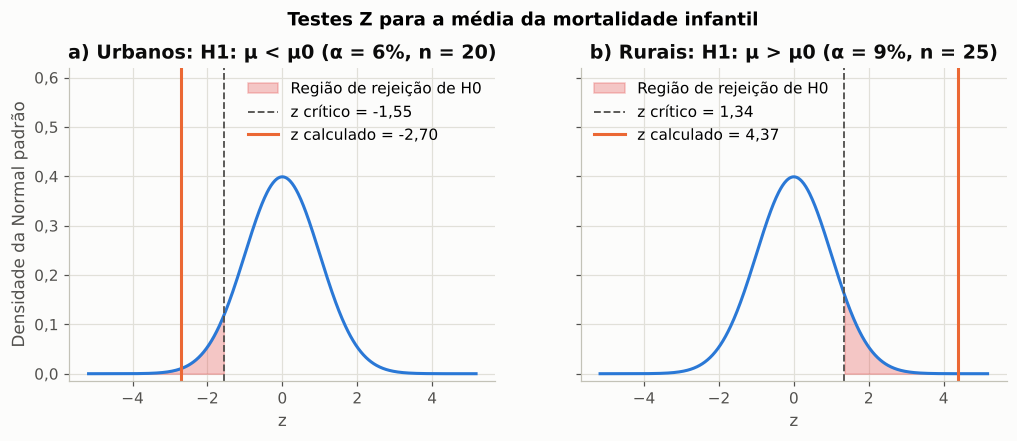

In [13]:
limite = max(4.0, abs(teste_a["z_calc"]) + 0.8, abs(teste_b["z_calc"]) + 0.8)
z = np.linspace(-limite, limite, 600)
fz = stats.norm.pdf(z)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
for ax, t, titulo in [
    (eixos[0], teste_a, "a) Urbanos: H1: μ < μ0 (α = 6%, n = 20)"),
    (eixos[1], teste_b, "b) Rurais: H1: μ > μ0 (α = 9%, n = 25)"),
]:
    regiao_critica = z <= t["z_crit"] if t["cauda"] == "esquerda" else z >= t["z_crit"]
    ax.plot(z, fz, color=AZUL, linewidth=2)
    ax.fill_between(z, fz, where=regiao_critica, color=VERMELHO, alpha=0.30, label="Região de rejeição de H0")
    ax.axvline(t["z_crit"], color=TINTA2, linestyle="--", linewidth=1.2, label=f"z crítico = {br(t['z_crit'], 2)}")
    ax.axvline(t["z_calc"], color=LARANJA, linewidth=2, label=f"z calculado = {br(t['z_calc'], 2)}")
    ax.set_title(titulo)
    ax.set_xlabel("z")
    ax.set_ylim(-0.015, 0.62)   # folga no topo para a legenda não cobrir a curva
    ax.yaxis.set_major_formatter(eixo_br(1))
    ax.legend(loc="upper right" if t["cauda"] == "esquerda" else "upper left")
eixos[0].set_ylabel("Densidade da Normal padrão")
fig.suptitle("Testes Z para a média da mortalidade infantil", fontweight="bold", y=1.02)
salvar_figura(fig, "fig03_testes_hipoteses.png")
plt.show()

---
## 04) Análise bivariada

**Variáveis quantitativas:**

- **X (explicativa):** `pct_banheiro_agua` — % da população em domicílios com banheiro e água encanada;
- **Y (resposta):** `mort_infantil` — óbitos de menores de 1 ano por mil nascidos vivos.

**Hipótese de trabalho:** municípios com maior cobertura de saneamento domiciliar apresentam menor mortalidade infantil.

### a) Gráfico de dispersão

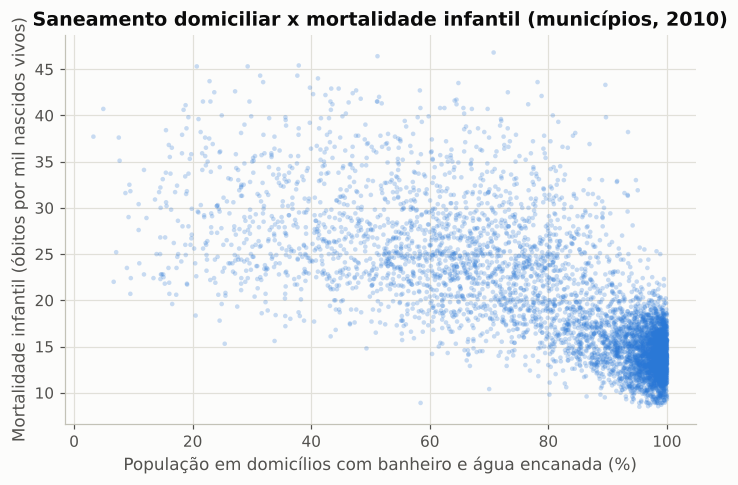

,municípios,mortalidade infantil média
pct_banheiro_agua,,
"(-0.001, 40.0]",389,"28,800"
"(40.0, 60.0]",604,"27,150"
"(60.0, 80.0]",1030,"24,330"
"(80.0, 90.0]",656,"19,510"
"(90.0, 95.0]",601,"15,660"
"(95.0, 100.0]",2285,"14,110"


INTERPRETAÇÃO
A nuvem de pontos é claramente descendente: quanto maior a cobertura de banheiro e água encanada, menor a
mortalidade infantil. Nos municípios com até 40% de cobertura a mortalidade média é de 28,8 por mil; nos que
têm mais de 95%, cai para 14,1.
Dois detalhes importantes: (1) há grande concentração de municípios perto de 100% de cobertura; (2) a queda
não é perfeitamente reta, sendo mais lenta abaixo de 60% e mais acentuada entre 60% e 95%. Além disso, a
dispersão vertical é grande em toda a faixa, sinal de que o saneamento sozinho não explica tudo.


In [14]:
X_SIMPLES = "pct_banheiro_agua"

fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.scatter(df[X_SIMPLES], df[VAR_Y], s=9, alpha=0.25, color=AZUL, edgecolors="none")
ax.set_title("Saneamento domiciliar x mortalidade infantil (municípios, 2010)")
ax.set_xlabel("População em domicílios com banheiro e água encanada (%)")
ax.set_ylabel("Mortalidade infantil (óbitos por mil nascidos vivos)")
salvar_figura(fig, "fig04_dispersao_simples.png")
plt.show()

faixas = pd.cut(df[X_SIMPLES], [0, 40, 60, 80, 90, 95, 100], include_lowest=True)
media_por_faixa = df.groupby(faixas, observed=True)[VAR_Y].agg(["size", "mean"]).rename(columns={"size": "municípios", "mean": "mortalidade infantil média"})
RESULTADOS["item04_faixas"] = {str(k): {"municipios": int(v["municípios"]), "media": float(v["mortalidade infantil média"])} for k, v in media_por_faixa.iterrows()}
display(media_por_faixa.round(2))

interpretar(f"""
A nuvem de pontos é claramente descendente: quanto maior a cobertura de banheiro e água encanada, menor a mortalidade infantil. Nos municípios com até 40% de cobertura a mortalidade média é de {br(media_por_faixa['mortalidade infantil média'].iloc[0], 1)} por mil; nos que têm mais de 95%, cai para {br(media_por_faixa['mortalidade infantil média'].iloc[-1], 1)}.
Dois detalhes importantes: (1) há grande concentração de municípios perto de 100% de cobertura; (2) a queda não é perfeitamente reta, sendo mais lenta abaixo de 60% e mais acentuada entre 60% e 95%. Além disso, a dispersão vertical é grande em toda a faixa, sinal de que o saneamento sozinho não explica tudo.
""")

### b) Covariância e correlação linear de Pearson

In [15]:
covariancia = df[X_SIMPLES].cov(df[VAR_Y])                      # covariância amostral (n - 1)
r_pearson, p_pearson = stats.pearsonr(df[X_SIMPLES], df[VAR_Y])

print(f"Covariância(X, Y)          = {br(covariancia, 4)}")
print(f"Correlação de Pearson (r)  = {br(r_pearson, 4)}")
print(f"p-valor do teste de r = 0  {fmt_p(p_pearson)}")

interpretar(f"""
A covariância é negativa ({br(covariancia, 2)}): as duas variáveis caminham em sentidos opostos. O valor em si não é interpretável como intensidade, porque depende das unidades (pontos percentuais x óbitos por mil).
A correlação de Pearson, que é a covariância padronizada, vale r = {br(r_pearson, 3)}: associação linear negativa e {forca_correlacao(r_pearson)}. O p-valor é praticamente zero, então a correlação é estatisticamente diferente de zero. Correlação não prova causa: municípios com mais saneamento também tendem a ser mais ricos e escolarizados (ver item 05).
""")

Covariância(X, Y)          = -114,5785
Correlação de Pearson (r)  = -0,7394
p-valor do teste de r = 0  < 0,0001
INTERPRETAÇÃO
A covariância é negativa (-114,58): as duas variáveis caminham em sentidos opostos. O valor em si não é
interpretável como intensidade, porque depende das unidades (pontos percentuais x óbitos por mil).
A correlação de Pearson, que é a covariância padronizada, vale r = -0,739: associação linear negativa e
forte. O p-valor é praticamente zero, então a correlação é estatisticamente diferente de zero. Correlação
não prova causa: municípios com mais saneamento também tendem a ser mais ricos e escolarizados (ver item
05).


### c) Gráfico de correlação linear de Pearson

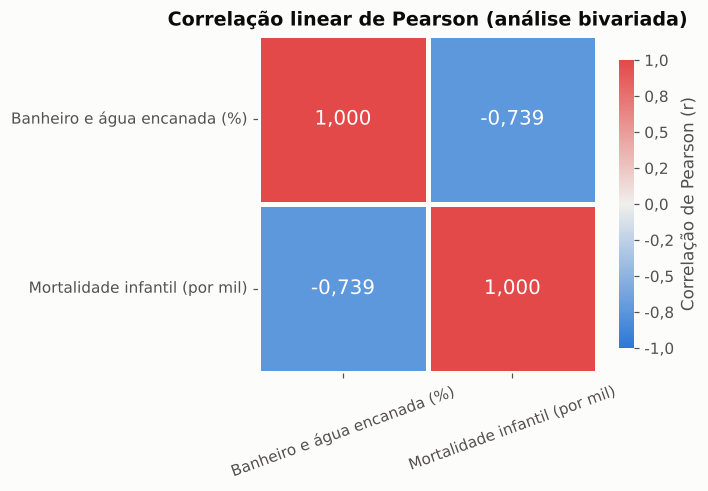

INTERPRETAÇÃO
O mapa de calor confirma visualmente o item b: fora da diagonal (onde cada variável se correlaciona
perfeitamente consigo mesma, r = 1), a célula que cruza saneamento e mortalidade infantil aparece em azul
intenso, cor reservada às correlações negativas, com r = -0,739.


In [16]:
matriz_corr_simples = df[[X_SIMPLES, VAR_Y]].rename(columns=ROTULOS).corr()

fig, ax = plt.subplots(figsize=(5.2, 4.0))
sns.heatmap(matriz_corr_simples, annot=matriz_corr_simples.map(lambda v: br(v, 3)), fmt="", cmap=MAPA_CORRELACAO, vmin=-1, vmax=1,
            square=True, linewidths=2, linecolor=FUNDO, annot_kws={"fontsize": 13},
            cbar_kws={"label": "Correlação de Pearson (r)", "shrink": 0.85, "format": eixo_br(1)}, ax=ax)
ax.set_title("Correlação linear de Pearson (análise bivariada)")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
salvar_figura(fig, "fig05_correlacao_bivariada.png")
plt.show()

interpretar(f"""
O mapa de calor confirma visualmente o item b: fora da diagonal (onde cada variável se correlaciona perfeitamente consigo mesma, r = 1), a célula que cruza saneamento e mortalidade infantil aparece em azul intenso, cor reservada às correlações negativas, com r = {br(r_pearson, 3)}.
""")

### d) Reta e equação da regressão linear simples

Equação da regressão linear simples:
   mort_infantil = 38,9024 + (-0,2430) x pct_banheiro_agua


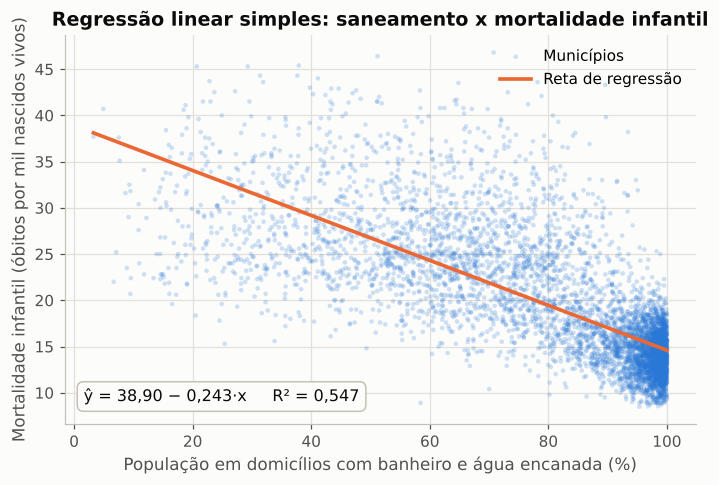

INTERPRETAÇÃO
Inclinação: cada 1 ponto percentual a mais de população com banheiro e água encanada está associado, em
média, a 0,243 óbito a menos por mil nascidos vivos; 10 pontos percentuais a mais correspondem a cerca de
2,4 óbitos a menos por mil.
Intercepto: 38,90 seria a mortalidade prevista para um município com 0% de cobertura. É uma extrapolação (o
mínimo observado é 3,3%) e serve apenas para posicionar a reta.


In [17]:
X1 = sm.add_constant(df[[X_SIMPLES]])
modelo_simples = sm.OLS(df[VAR_Y], X1).fit()
b0_s, b1_s = modelo_simples.params["const"], modelo_simples.params[X_SIMPLES]

print("Equação da regressão linear simples:")
print(f"   mort_infantil = {br(b0_s, 4)} + ({br(b1_s, 4)}) x pct_banheiro_agua")

xs = np.linspace(df[X_SIMPLES].min(), df[X_SIMPLES].max(), 100)
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.scatter(df[X_SIMPLES], df[VAR_Y], s=9, alpha=0.22, color=AZUL, edgecolors="none", label="Municípios")
ax.plot(xs, b0_s + b1_s * xs, color=LARANJA, linewidth=2.4, label="Reta de regressão")
ax.text(0.03, 0.06, f"ŷ = {br(b0_s, 2)} − {br(abs(b1_s), 3)}·x     R² = {br(modelo_simples.rsquared, 3)}",
        transform=ax.transAxes, fontsize=10.5, color=TINTA,
        bbox={"facecolor": FUNDO, "edgecolor": EIXO, "boxstyle": "round,pad=0.4"})
ax.set_title("Regressão linear simples: saneamento x mortalidade infantil")
ax.set_xlabel("População em domicílios com banheiro e água encanada (%)")
ax.set_ylabel("Mortalidade infantil (óbitos por mil nascidos vivos)")
ax.legend(loc="upper right")
salvar_figura(fig, "fig06_regressao_simples.png")
plt.show()

interpretar(f"""
Inclinação: cada 1 ponto percentual a mais de população com banheiro e água encanada está associado, em média, a {br(abs(b1_s), 3)} óbito a menos por mil nascidos vivos; 10 pontos percentuais a mais correspondem a cerca de {br(abs(10 * b1_s), 1)} óbitos a menos por mil.
Intercepto: {br(b0_s, 2)} seria a mortalidade prevista para um município com 0% de cobertura. É uma extrapolação (o mínimo observado é {br(df[X_SIMPLES].min(), 1)}%) e serve apenas para posicionar a reta.
""")

### e) Adequação do modelo: R² e teste F

In [18]:
print(modelo_simples.summary().tables[0])
print(modelo_simples.summary().tables[1])

r2_s, f_s, pf_s = modelo_simples.rsquared, modelo_simples.fvalue, modelo_simples.f_pvalue
print(f"\nR² = {br(r2_s, 4)}")
print(f"Teste F: F({int(modelo_simples.df_model)}, {int(modelo_simples.df_resid)}) = {br(f_s, 2)} | p-valor {fmt_p(pf_s)}")

interpretar(f"""
R² = {br(r2_s, 3)}: a cobertura de banheiro e água encanada, sozinha, explica {br(100 * r2_s, 1)}% da variação da mortalidade infantil entre os municípios. Os outros {br(100 * (1 - r2_s), 1)}% ficam por conta de fatores que não estão no modelo.
Teste F (H0: o modelo não tem poder explicativo, isto é, inclinação = 0): F = {br(f_s, 1)} com p-valor praticamente nulo, muito abaixo de 0,05. Rejeita-se H0: o modelo é estatisticamente significativo. Com mais de 5 mil observações, porém, quase qualquer associação seria significativa; por isso o R² e o tamanho do efeito importam mais do que o p-valor.
""")

                            OLS Regression Results                            
Dep. Variable:          mort_infantil   R-squared:                       0.547
Model:                            OLS   Adj. R-squared:                  0.547
Method:                 Least Squares   F-statistic:                     6711.
Date:                Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:09:51   Log-Likelihood:                -16631.
No. Observations:                5565   AIC:                         3.327e+04
Df Residuals:                    5563   BIC:                         3.328e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                38.9024      0.24

### f) Previsão

In [19]:
X_NOVO_SIMPLES = 60.0   # município hipotético com 60% da população com banheiro e água encanada
novo = pd.DataFrame({"const": [1.0], X_SIMPLES: [X_NOVO_SIMPLES]})
previsao_s = modelo_simples.get_prediction(novo).summary_frame(alpha=0.05).iloc[0]

X_COMPARACAO = 95.0
previsao_s_comp = float(b0_s + b1_s * X_COMPARACAO)

print(f"Previsão para pct_banheiro_agua = {br(X_NOVO_SIMPLES, 0)}%:")
print(f"   mort_infantil = {br(b0_s, 4)} + ({br(b1_s, 4)}) x {br(X_NOVO_SIMPLES, 0)} = {br(previsao_s['mean'], 2)} óbitos por mil")
print(f"   Intervalo de previsão de 95% para um município: [{br(previsao_s['obs_ci_lower'], 2)} ; {br(previsao_s['obs_ci_upper'], 2)}]")
print(f"Comparação, para pct_banheiro_agua = {br(X_COMPARACAO, 0)}%: {br(previsao_s_comp, 2)} óbitos por mil")

interpretar(f"""
Para um município em que 60% da população vive em domicílios com banheiro e água encanada, o modelo prevê {br(previsao_s['mean'], 1)} óbitos por mil nascidos vivos, acima da meta ODM de {br(META_ODM, 1)}. Para um município com 95% de cobertura, a previsão cai para {br(previsao_s_comp, 1)}.
O intervalo de previsão de 95% ({br(previsao_s['obs_ci_lower'], 1)} a {br(previsao_s['obs_ci_upper'], 1)}) é largo: o modelo indica o nível médio esperado, mas não substitui o dado real de cada município. A previsão é válida apenas dentro da faixa observada de X ({br(df[X_SIMPLES].min(), 1)}% a {br(df[X_SIMPLES].max(), 0)}%).
""")

RESULTADOS["item04"] = {
    "x": X_SIMPLES, "y": VAR_Y, "covariancia": float(covariancia), "r": float(r_pearson),
    "p_r": float(p_pearson), "forca": forca_correlacao(r_pearson),
    "b0": float(b0_s), "b1": float(b1_s), "r2": float(r2_s), "f": float(f_s), "p_f": float(pf_s),
    "gl_modelo": int(modelo_simples.df_model), "gl_residuo": int(modelo_simples.df_resid),
    "x_novo": X_NOVO_SIMPLES, "previsao": float(previsao_s["mean"]),
    "ip_inf": float(previsao_s["obs_ci_lower"]), "ip_sup": float(previsao_s["obs_ci_upper"]),
    "x_comparacao": X_COMPARACAO, "previsao_comparacao": previsao_s_comp,
    "x_min": float(df[X_SIMPLES].min()), "x_max": float(df[X_SIMPLES].max()),
}

Previsão para pct_banheiro_agua = 60%:
   mort_infantil = 38,9024 + (-0,2430) x 60 = 24,32 óbitos por mil
   Intervalo de previsão de 95% para um município: [14,90 ; 33,74]
Comparação, para pct_banheiro_agua = 95%: 15,81 óbitos por mil
INTERPRETAÇÃO
Para um município em que 60% da população vive em domicílios com banheiro e água encanada, o modelo prevê
24,3 óbitos por mil nascidos vivos, acima da meta ODM de 15,7. Para um município com 95% de cobertura, a
previsão cai para 15,8.
O intervalo de previsão de 95% (14,9 a 33,7) é largo: o modelo indica o nível médio esperado, mas não
substitui o dado real de cada município. A previsão é válida apenas dentro da faixa observada de X (3,3% a
100%).


---
## 05) Regressão linear múltipla

**Variáveis quantitativas (4):**

- **Y:** `mort_infantil`
- **X₁:** `pct_banheiro_agua` (saneamento)
- **X₂:** `taxa_analfabetismo` (educação)
- **X₃:** `renda_per_capita` (renda)

**Motivação:** o item 04 mostrou que o saneamento explica pouco mais da metade da variação. Educação e renda são candidatas naturais a explicar o restante — e também a "confundir" o efeito do saneamento, já que andam juntas com ele.

### a) Gráficos de dispersão

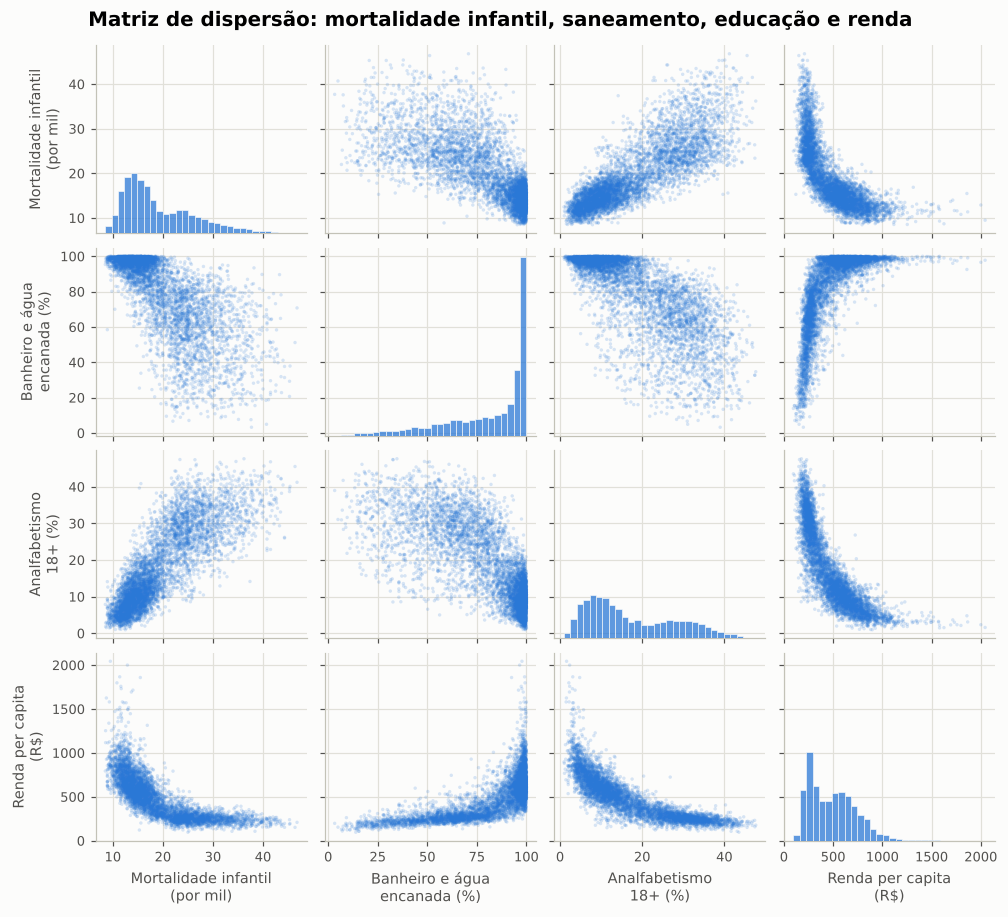

Mortalidade infantil média por faixa de renda per capita (R$):
renda_per_capita
(0, 250]      28,450
(250, 400]    23,790
(400, 600]    16,040
(600, 800]    13,830
(800, 2100]   12,270
INTERPRETAÇÃO
Primeira linha (Y contra cada X): a mortalidade infantil cai com o saneamento e com a renda, e sobe de forma
bem alinhada com o analfabetismo, que é a relação mais próxima de uma reta. A relação com a renda é curva: a
média cai de 28,5 (até R$ 250) para 16,0 (R$ 400 a 600), mas depois cai bem mais devagar: 13,8 (R$ 600 a
800) e 12,3 (acima de R$ 800).
Entre as explicativas: saneamento, analfabetismo e renda também estão fortemente relacionados entre si
(municípios pobres tendem a ter pior saneamento e mais analfabetismo). Isso indica multicolinearidade,
verificada adiante pelo VIF.


In [20]:
dados_multi = df[[VAR_Y] + VARS_X]

ROTULOS_2_LINHAS = {
    "mort_infantil": "Mortalidade infantil\n(por mil)",
    "pct_banheiro_agua": "Banheiro e água\nencanada (%)",
    "taxa_analfabetismo": "Analfabetismo\n18+ (%)",
    "renda_per_capita": "Renda per capita\n(R$)",
}
grade_pares = sns.pairplot(
    dados_multi.rename(columns=ROTULOS_2_LINHAS), height=2.05, aspect=1.15, diag_kind="hist",
    plot_kws={"s": 5, "alpha": 0.18, "color": AZUL, "edgecolor": "none"},
    diag_kws={"color": AZUL, "edgecolor": FUNDO, "bins": 30},
)
for ax in grade_pares.axes.flatten():
    ax.xaxis.label.set_size(9.5)
    ax.yaxis.label.set_size(9.5)
    ax.tick_params(labelsize=8.5)
grade_pares.figure.suptitle("Matriz de dispersão: mortalidade infantil, saneamento, educação e renda",
                             fontweight="bold", fontsize=13, y=1.02)
salvar_figura(grade_pares.figure, "fig07_dispersao_multipla.png")
plt.show()

faixas_renda = pd.cut(df["renda_per_capita"], [0, 250, 400, 600, 800, 2100])
media_por_renda = df.groupby(faixas_renda, observed=True)[VAR_Y].mean()
print("Mortalidade infantil média por faixa de renda per capita (R$):")
print(media_por_renda.round(2).to_string())

interpretar(f"""
Primeira linha (Y contra cada X): a mortalidade infantil cai com o saneamento e com a renda, e sobe de forma bem alinhada com o analfabetismo, que é a relação mais próxima de uma reta. A relação com a renda é curva: a média cai de {br(media_por_renda.iloc[0], 1)} (até R$ 250) para {br(media_por_renda.iloc[2], 1)} (R$ 400 a 600), mas depois cai bem mais devagar: {br(media_por_renda.iloc[3], 1)} (R$ 600 a 800) e {br(media_por_renda.iloc[4], 1)} (acima de R$ 800).
Entre as explicativas: saneamento, analfabetismo e renda também estão fortemente relacionados entre si (municípios pobres tendem a ter pior saneamento e mais analfabetismo). Isso indica multicolinearidade, verificada adiante pelo VIF.
""")

### b) Matriz de covariância e matriz de correlação linear de Pearson

In [21]:
matriz_cov = dados_multi.cov()
matriz_corr = dados_multi.corr()

print("Matriz de covariância (amostral):")
display(matriz_cov.round(3))
print("Matriz de correlação linear de Pearson:")
display(matriz_corr.round(3))

corr_y = matriz_corr[VAR_Y].drop(VAR_Y)
interpretar(f"""
Covariâncias: os sinais mostram o sentido das relações (mortalidade infantil covaria negativamente com saneamento e renda e positivamente com analfabetismo), mas as magnitudes não são comparáveis entre si porque dependem das unidades. A variância da renda ({br(matriz_cov.loc['renda_per_capita', 'renda_per_capita'], 0)}) é enorme simplesmente porque a renda é medida em reais.
Correlações com a mortalidade infantil: analfabetismo r = {br(corr_y['taxa_analfabetismo'], 3)} (a mais forte), renda r = {br(corr_y['renda_per_capita'], 3)} e saneamento r = {br(corr_y['pct_banheiro_agua'], 3)}. As três são fortes e têm o sinal esperado.
Correlações entre as explicativas: saneamento x analfabetismo r = {br(matriz_corr.loc['pct_banheiro_agua', 'taxa_analfabetismo'], 3)}; analfabetismo x renda r = {br(matriz_corr.loc['taxa_analfabetismo', 'renda_per_capita'], 3)}; saneamento x renda r = {br(matriz_corr.loc['pct_banheiro_agua', 'renda_per_capita'], 3)}. Como elas se sobrepõem, parte do que o modelo simples atribuía ao saneamento é, na verdade, compartilhada com educação e renda.
""")

Matriz de covariância (amostral):


,mort_infantil,pct_banheiro_agua,taxa_analfabetismo,renda_per_capita
mort_infantil,"50,932","-114,579","63,139","-1.290,998"
pct_banheiro_agua,"-114,579","471,431","-173,808","3.696,084"
taxa_analfabetismo,"63,139","-173,808","114,468","-2.127,840"
renda_per_capita,"-1.290,998","3.696,084","-2.127,840","59.179,969"


Matriz de correlação linear de Pearson:


,mort_infantil,pct_banheiro_agua,taxa_analfabetismo,renda_per_capita
mort_infantil,"1,000","-0,739","0,827","-0,744"
pct_banheiro_agua,"-0,739","1,000","-0,748","0,700"
taxa_analfabetismo,"0,827","-0,748","1,000","-0,818"
renda_per_capita,"-0,744","0,700","-0,818","1,000"


INTERPRETAÇÃO
Covariâncias: os sinais mostram o sentido das relações (mortalidade infantil covaria negativamente com
saneamento e renda e positivamente com analfabetismo), mas as magnitudes não são comparáveis entre si porque
dependem das unidades. A variância da renda (59.180) é enorme simplesmente porque a renda é medida em reais.
Correlações com a mortalidade infantil: analfabetismo r = 0,827 (a mais forte), renda r = -0,744 e
saneamento r = -0,739. As três são fortes e têm o sinal esperado.
Correlações entre as explicativas: saneamento x analfabetismo r = -0,748; analfabetismo x renda r = -0,818;
saneamento x renda r = 0,700. Como elas se sobrepõem, parte do que o modelo simples atribuía ao saneamento
é, na verdade, compartilhada com educação e renda.


### c) Gráfico de correlação linear de Pearson

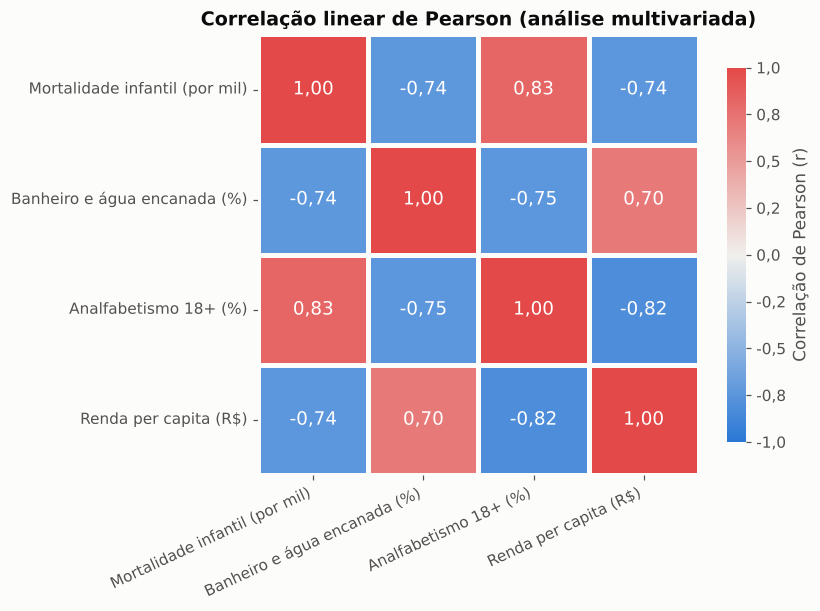

INTERPRETAÇÃO
O mapa separa dois blocos: vermelho (correlação positiva) entre mortalidade infantil e analfabetismo e entre
saneamento e renda; azul (correlação negativa) em todos os cruzamentos que opõem um indicador de carência
(mortalidade, analfabetismo) a um indicador de bem-estar (saneamento, renda). Nenhuma célula fora da
diagonal é clara: a menor correlação em módulo é 0,70, isto é, todos os pares de variáveis estão fortemente
associados, o que reforça a necessidade da leitura conjunta feita pela regressão múltipla.


In [22]:
fig, ax = plt.subplots(figsize=(6.6, 5.2))
sns.heatmap(matriz_corr.rename(index=ROTULOS, columns=ROTULOS), annot=matriz_corr.map(lambda v: br(v, 2)), fmt="",
            cmap=MAPA_CORRELACAO, vmin=-1, vmax=1, square=True, linewidths=2, linecolor=FUNDO,
            annot_kws={"fontsize": 12}, cbar_kws={"label": "Correlação de Pearson (r)", "shrink": 0.85, "format": eixo_br(1)}, ax=ax)
ax.set_title("Correlação linear de Pearson (análise multivariada)")
ax.tick_params(axis="x", rotation=25)
ax.tick_params(axis="y", rotation=0)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(False)
salvar_figura(fig, "fig08_correlacao_multipla.png")
plt.show()

menor_corr = float(np.abs(matriz_corr.values[np.triu_indices(len(matriz_corr), k=1)]).min())
interpretar(f"""
O mapa separa dois blocos: vermelho (correlação positiva) entre mortalidade infantil e analfabetismo e entre saneamento e renda; azul (correlação negativa) em todos os cruzamentos que opõem um indicador de carência (mortalidade, analfabetismo) a um indicador de bem-estar (saneamento, renda). Nenhuma célula fora da diagonal é clara: a menor correlação em módulo é {br(menor_corr, 2)}, isto é, todos os pares de variáveis estão fortemente associados, o que reforça a necessidade da leitura conjunta feita pela regressão múltipla.
""")

### d) Equação da regressão linear múltipla

In [23]:
X_multi = sm.add_constant(df[VARS_X])
modelo_multiplo = sm.OLS(df[VAR_Y], X_multi).fit()
bm = modelo_multiplo.params

print("Equação da regressão linear múltipla:")
print(f"   mort_infantil = {br(bm['const'], 4)}"
      f" + ({br(bm['pct_banheiro_agua'], 4)}) x pct_banheiro_agua"
      f" + ({br(bm['taxa_analfabetismo'], 4)}) x taxa_analfabetismo"
      f" + ({br(bm['renda_per_capita'], 5)}) x renda_per_capita")

# Coeficientes padronizados (beta): efeito de 1 desvio padrão de X, em desvios padrão de Y
betas = {v: float(bm[v] * df[v].std() / df[VAR_Y].std()) for v in VARS_X}
print("\nCoeficientes padronizados (comparáveis entre si):")
for v, b in betas.items():
    print(f"   {v:<20} {br(b, 3, sinal=True)}")

interpretar(f"""
Mantidas as outras duas variáveis constantes: (i) cada 1 ponto percentual a mais de população com banheiro e água encanada está associado a {br(abs(bm['pct_banheiro_agua']), 3)} óbito a menos por mil; (ii) cada 1 ponto percentual a mais de analfabetismo adulto, a {br(bm['taxa_analfabetismo'], 3)} óbito a mais por mil; (iii) cada R$ 100 a mais de renda per capita, a {br(abs(100 * bm['renda_per_capita']), 2)} óbito a menos por mil.
O coeficiente do saneamento caiu de {br(b1_s, 3)} (modelo simples) para {br(bm['pct_banheiro_agua'], 3)}: ou seja, {br(100 * (1 - bm['pct_banheiro_agua'] / b1_s), 0)}% da associação aparente do saneamento no modelo simples era compartilhada com educação e renda. Pelos coeficientes padronizados, o analfabetismo é a variável de maior peso ({br(betas['taxa_analfabetismo'], 2, sinal=True)}), seguido de saneamento ({br(betas['pct_banheiro_agua'], 2, sinal=True)}) e renda ({br(betas['renda_per_capita'], 2, sinal=True)}).
""")

Equação da regressão linear múltipla:
   mort_infantil = 21,6584 + (-0,0811) x pct_banheiro_agua + (0,3531) x taxa_analfabetismo + (-0,00406) x renda_per_capita

Coeficientes padronizados (comparáveis entre si):
   pct_banheiro_agua    -0,247
   taxa_analfabetismo   +0,529
   renda_per_capita     -0,138
INTERPRETAÇÃO
Mantidas as outras duas variáveis constantes: (i) cada 1 ponto percentual a mais de população com banheiro e
água encanada está associado a 0,081 óbito a menos por mil; (ii) cada 1 ponto percentual a mais de
analfabetismo adulto, a 0,353 óbito a mais por mil; (iii) cada R$ 100 a mais de renda per capita, a 0,41
óbito a menos por mil.
O coeficiente do saneamento caiu de -0,243 (modelo simples) para -0,081: ou seja, 67% da associação aparente
do saneamento no modelo simples era compartilhada com educação e renda. Pelos coeficientes padronizados, o
analfabetismo é a variável de maior peso (+0,53), seguido de saneamento (-0,25) e renda (-0,14).


### e) Adequação do modelo: R² e teste F

In [24]:
print(modelo_multiplo.summary().tables[0])
print(modelo_multiplo.summary().tables[1])

r2_m, r2aj_m = modelo_multiplo.rsquared, modelo_multiplo.rsquared_adj
f_m, pf_m = modelo_multiplo.fvalue, modelo_multiplo.f_pvalue
print(f"\nR² = {br(r2_m, 4)} | R² ajustado = {br(r2aj_m, 4)}")
print(f"Teste F: F({int(modelo_multiplo.df_model)}, {int(modelo_multiplo.df_resid)}) = {br(f_m, 2)} | p-valor {fmt_p(pf_m)}")

# Diagnósticos complementares
vif = {v: float(variance_inflation_factor(X_multi.values, i + 1)) for i, v in enumerate(VARS_X)}
bp_lm, bp_p, _, _ = het_breuschpagan(modelo_multiplo.resid, X_multi)
modelo_robusto = modelo_multiplo.get_robustcov_results(cov_type="HC3")
p_robustos = dict(zip(X_multi.columns, [float(p) for p in modelo_robusto.pvalues]))

print("\nVIF (multicolinearidade; valores acima de 5 merecem atenção):")
for v, valor in vif.items():
    print(f"   {v:<20} {br(valor, 2)}")
print(f"\nBreusch-Pagan (H0: variância constante dos resíduos): LM = {br(bp_lm, 1)} | p-valor {fmt_p(bp_p)}")
print("p-valores dos coeficientes com erros padrão robustos (HC3):")
for v in VARS_X:
    print(f"   {v:<20} {fmt_p(p_robustos[v], com_sinal=False)}")

interpretar(f"""
R² = {br(r2_m, 3)} (ajustado = {br(r2aj_m, 3)}): saneamento, educação e renda explicam em conjunto {br(100 * r2_m, 1)}% da variação da mortalidade infantil entre os municípios, contra {br(100 * r2_s, 1)}% do modelo simples. O R² ajustado praticamente igual ao R² mostra que o ganho não é artefato do número de variáveis.
Teste F (H0: todos os coeficientes das explicativas são zero): F = {br(f_m, 1)}, p-valor praticamente nulo. Rejeita-se H0: o modelo como um todo é significativo. Individualmente, os três coeficientes também são significativos (p < 0,001 nos testes t).
Diagnósticos: os VIFs ficam entre {br(min(vif.values()), 1)} e {br(max(vif.values()), 1)}, abaixo de 5; há multicolinearidade moderada, mas sem comprometer o modelo. O teste de Breusch-Pagan rejeita a variância constante dos resíduos (heterocedasticidade), por isso os p-valores foram recalculados com erros padrão robustos e continuaram significativos.
""")

                            OLS Regression Results                            
Dep. Variable:          mort_infantil   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     4836.
Date:                Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:09:53   Log-Likelihood:                -15261.
No. Observations:                5565   AIC:                         3.053e+04
Df Residuals:                    5561   BIC:                         3.056e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 21.6584      0


VIF (multicolinearidade; valores acima de 5 merecem atenção):
   pct_banheiro_agua    2,40
   taxa_analfabetismo   3,69
   renda_per_capita     3,18

Breusch-Pagan (H0: variância constante dos resíduos): LM = 804,7 | p-valor < 0,0001
p-valores dos coeficientes com erros padrão robustos (HC3):
   pct_banheiro_agua    < 0,0001
   taxa_analfabetismo   < 0,0001
   renda_per_capita     < 0,0001
INTERPRETAÇÃO
R² = 0,723 (ajustado = 0,723): saneamento, educação e renda explicam em conjunto 72,3% da variação da
mortalidade infantil entre os municípios, contra 54,7% do modelo simples. O R² ajustado praticamente igual
ao R² mostra que o ganho não é artefato do número de variáveis.
Teste F (H0: todos os coeficientes das explicativas são zero): F = 4.836,1, p-valor praticamente nulo.
Rejeita-se H0: o modelo como um todo é significativo. Individualmente, os três coeficientes também são
significativos (p < 0,001 nos testes t).
Diagnósticos: os VIFs ficam entre 2,4 e 3,7, abaixo de 5; há multicoline

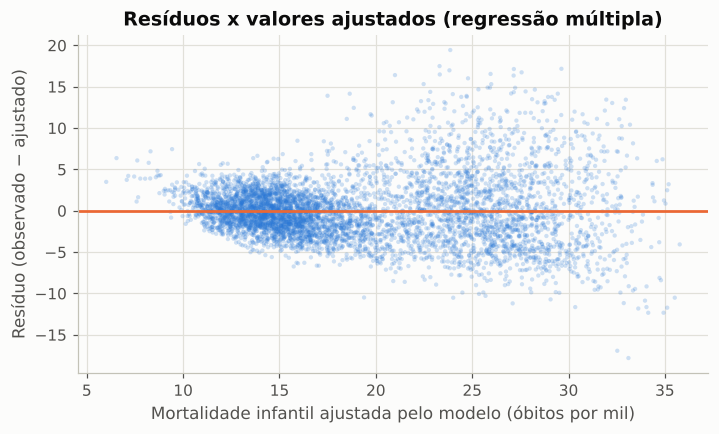

INTERPRETAÇÃO
Os resíduos se distribuem em torno de zero, mas a dispersão aumenta para valores ajustados mais altos
(formato de leque) e há mais resíduos positivos grandes do que negativos. Ou seja: o modelo acerta melhor os
municípios de baixa mortalidade e erra mais nos de alta mortalidade. O erro típico (desvio padrão dos
resíduos) é de 3,76 óbitos por mil.


In [25]:
fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.scatter(modelo_multiplo.fittedvalues, modelo_multiplo.resid, s=8, alpha=0.22, color=AZUL, edgecolors="none")
ax.axhline(0, color=LARANJA, linewidth=1.8)
ax.set_title("Resíduos x valores ajustados (regressão múltipla)")
ax.set_xlabel("Mortalidade infantil ajustada pelo modelo (óbitos por mil)")
ax.set_ylabel("Resíduo (observado − ajustado)")
salvar_figura(fig, "fig09_residuos_multipla.png")
plt.show()

dp_residuos = float(np.sqrt(modelo_multiplo.scale))
interpretar(f"""
Os resíduos se distribuem em torno de zero, mas a dispersão aumenta para valores ajustados mais altos (formato de leque) e há mais resíduos positivos grandes do que negativos. Ou seja: o modelo acerta melhor os municípios de baixa mortalidade e erra mais nos de alta mortalidade. O erro típico (desvio padrão dos resíduos) é de {br(dp_residuos, 2)} óbitos por mil.
""")

### f) Previsão com as variáveis explicativas

In [26]:
CENARIO_A = {"pct_banheiro_agua": 60.0, "taxa_analfabetismo": 25.0, "renda_per_capita": 300.0}
CENARIO_B = {"pct_banheiro_agua": 95.0, "taxa_analfabetismo": 8.0, "renda_per_capita": 700.0}


def prever_multipla(cenario):
    linha = pd.DataFrame({"const": [1.0], **{k: [v] for k, v in cenario.items()}})[X_multi.columns]
    return modelo_multiplo.get_prediction(linha).summary_frame(alpha=0.05).iloc[0]


prev_a, prev_b = prever_multipla(CENARIO_A), prever_multipla(CENARIO_B)
for nome, cenario, prev in [("A (carência)", CENARIO_A, prev_a), ("B (boa cobertura)", CENARIO_B, prev_b)]:
    print(f"Município {nome}: banheiro e água = {br(cenario['pct_banheiro_agua'], 0)}% | "
          f"analfabetismo = {br(cenario['taxa_analfabetismo'], 0)}% | renda = R$ {br(cenario['renda_per_capita'], 0)}")
    print(f"   mort_infantil prevista = {br(prev['mean'], 2)} óbitos por mil "
          f"(intervalo de previsão de 95%: {br(prev['obs_ci_lower'], 2)} a {br(prev['obs_ci_upper'], 2)})")

interpretar(f"""
Município A (60% de cobertura de banheiro e água, 25% de analfabetismo adulto e renda per capita de R$ 300): o modelo prevê {br(prev_a['mean'], 1)} óbitos por mil nascidos vivos, bem acima da meta ODM de {br(META_ODM, 1)}.
Município B (95%, 8% e R$ 700): a previsão é de {br(prev_b['mean'], 1)} por mil, abaixo da meta. A diferença de {br(prev_a['mean'] - prev_b['mean'], 1)} óbitos por mil entre os dois perfis resume o tamanho da desigualdade associada a esses três fatores.
As previsões descrevem o nível médio de municípios com esses perfis; não significam que alterar um indicador isoladamente produzirá exatamente esse efeito (o modelo mede associação, não causa).
""")

RESULTADOS["item05"] = {
    "variaveis_x": VARS_X, "cov": matriz_cov.round(4).to_dict(), "corr": matriz_corr.round(4).to_dict(),
    "coef": {k: float(v) for k, v in bm.items()}, "betas": betas,
    "p_coef": {k: float(v) for k, v in modelo_multiplo.pvalues.items()},
    "r2": float(r2_m), "r2_ajustado": float(r2aj_m), "f": float(f_m), "p_f": float(pf_m),
    "gl_modelo": int(modelo_multiplo.df_model), "gl_residuo": int(modelo_multiplo.df_resid),
    "vif": vif, "bp_lm": float(bp_lm), "bp_p": float(bp_p), "p_robustos": p_robustos,
    "dp_residuos": dp_residuos,
    "cenario_a": CENARIO_A, "prev_a": float(prev_a["mean"]),
    "prev_a_inf": float(prev_a["obs_ci_lower"]), "prev_a_sup": float(prev_a["obs_ci_upper"]),
    "cenario_b": CENARIO_B, "prev_b": float(prev_b["mean"]),
    "prev_b_inf": float(prev_b["obs_ci_lower"]), "prev_b_sup": float(prev_b["obs_ci_upper"]),
}

Município A (carência): banheiro e água = 60% | analfabetismo = 25% | renda = R$ 300
   mort_infantil prevista = 24,41 óbitos por mil (intervalo de previsão de 95%: 17,04 a 31,77)
Município B (boa cobertura): banheiro e água = 95% | analfabetismo = 8% | renda = R$ 700
   mort_infantil prevista = 13,94 óbitos por mil (intervalo de previsão de 95%: 6,58 a 21,31)
INTERPRETAÇÃO
Município A (60% de cobertura de banheiro e água, 25% de analfabetismo adulto e renda per capita de R$ 300):
o modelo prevê 24,4 óbitos por mil nascidos vivos, bem acima da meta ODM de 15,7.
Município B (95%, 8% e R$ 700): a previsão é de 13,9 por mil, abaixo da meta. A diferença de 10,5 óbitos por
mil entre os dois perfis resume o tamanho da desigualdade associada a esses três fatores.
As previsões descrevem o nível médio de municípios com esses perfis; não significam que alterar um indicador
isoladamente produzirá exatamente esse efeito (o modelo mede associação, não causa).


---
## 06) Regressão logística binária

**Variável resposta (binária):** `alta_mortalidade` = 1 se a mortalidade infantil do município está **acima da meta ODM de 15,7 por mil**; 0 caso contrário.

**Variáveis explicativas quantitativas (3):** `pct_banheiro_agua`, `taxa_analfabetismo` e `renda_per_capita`.

**Pergunta:** conhecendo apenas saneamento, educação e renda de um município, é possível classificá-lo corretamente como acima ou abaixo da meta? Um classificador assim permite **triagem de municípios prioritários** quando o indicador de mortalidade não está disponível ou está defasado.

**Procedimento:** a base é dividida em **treino (70%)** e **teste (30%)**, de forma estratificada e com semente fixa. O modelo é ajustado no treino e avaliado no teste, isto é, em municípios que ele "nunca viu".

In [27]:
VAR_BINARIA = "alta_mortalidade"

X_log = sm.add_constant(df[VARS_X])
y_log = df[VAR_BINARIA]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_log, y_log, test_size=0.30, random_state=SEMENTE, stratify=y_log)

print(f"Treino: {len(X_treino)} municípios | Teste: {len(X_teste)} municípios")
print(f"Proporção de alta mortalidade -> base: {br(y_log.mean(), 3)} | treino: {br(y_treino.mean(), 3)} | teste: {br(y_teste.mean(), 3)}")

Treino: 3895 municípios | Teste: 1670 municípios
Proporção de alta mortalidade -> base: 0,585 | treino: 0,585 | teste: 0,585


### a) Equação da regressão logística binária

In [28]:
modelo_logistico = sm.Logit(y_treino, X_treino).fit(disp=False)
bl = modelo_logistico.params
print(modelo_logistico.summary().tables[1])

print("\nEquação da regressão logística binária (logito):")
print(f"   ln(p / (1 - p)) = {br(bl['const'], 4)}"
      f" + ({br(bl['pct_banheiro_agua'], 4)}) x pct_banheiro_agua"
      f" + ({br(bl['taxa_analfabetismo'], 4)}) x taxa_analfabetismo"
      f" + ({br(bl['renda_per_capita'], 5)}) x renda_per_capita")
print("\nEm termos de probabilidade:")
print("   p = P(alta_mortalidade = 1) = 1 / (1 + e^(-logito))")

razoes_chance = np.exp(bl)
print("\nRazões de chance (odds ratio = e^coeficiente):")
for v in VARS_X:
    print(f"   {v:<20} {br(razoes_chance[v], 4)}")
print(f"   renda_per_capita (a cada R$ 100) {br(np.exp(100 * bl['renda_per_capita']), 4)}")
print(f"\nPseudo R² de McFadden = {br(modelo_logistico.prsquared, 4)} | p-valor do teste da razão de verossimilhança {fmt_p(modelo_logistico.llr_pvalue)}")

interpretar(f"""
p é a probabilidade de o município estar acima da meta ODM. Mantidas as demais variáveis constantes: cada 1 ponto percentual a mais de população com banheiro e água encanada multiplica a chance de alta mortalidade por {br(razoes_chance['pct_banheiro_agua'], 3)} (redução de {br(100 * (1 - razoes_chance['pct_banheiro_agua']), 1)}%); cada 1 ponto percentual a mais de analfabetismo multiplica a chance por {br(razoes_chance['taxa_analfabetismo'], 3)} (aumento de {br(100 * (razoes_chance['taxa_analfabetismo'] - 1), 1)}%); cada R$ 100 a mais de renda per capita multiplica a chance por {br(np.exp(100 * bl['renda_per_capita']), 3)} (redução de {br(100 * (1 - np.exp(100 * bl['renda_per_capita'])), 1)}%).
Os três coeficientes são estatisticamente significativos (p < 0,001) e têm os mesmos sinais da regressão linear múltipla, o que dá coerência ao conjunto das análises.
""")

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  6.3953      0.692      9.237      0.000       5.038       7.752
pct_banheiro_agua     -0.0500      0.006     -7.855      0.000      -0.062      -0.037
taxa_analfabetismo     0.1050      0.014      7.744      0.000       0.078       0.132
renda_per_capita      -0.0059      0.001    -11.645      0.000      -0.007      -0.005

Equação da regressão logística binária (logito):
   ln(p / (1 - p)) = 6,3953 + (-0,0500) x pct_banheiro_agua + (0,1050) x taxa_analfabetismo + (-0,00592) x renda_per_capita

Em termos de probabilidade:
   p = P(alta_mortalidade = 1) = 1 / (1 + e^(-logito))

Razões de chance (odds ratio = e^coeficiente):
   pct_banheiro_agua    0,9513
   taxa_analfabetismo   1,1107
   renda_per_capita     0,9941
   renda_per_capita (a cada R$ 100) 0,5530

Pseudo R² de McFadden = 0,5268 | p-

### b) Matriz de confusão e acurácia

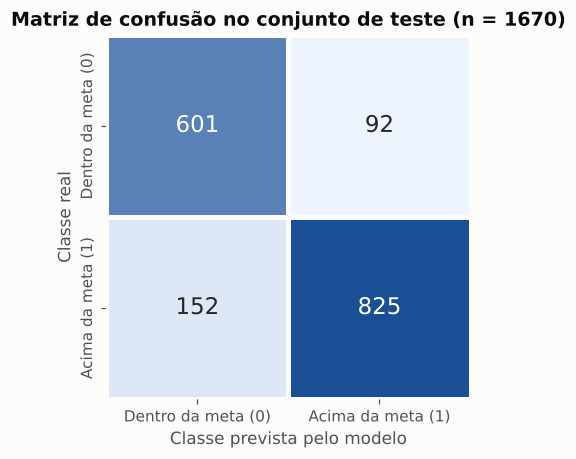

Verdadeiros negativos (VN) = 601 | Falsos positivos (FP) = 92
Falsos negativos (FN)      = 152 | Verdadeiros positivos (VP) = 825

Acurácia no teste  = (VP + VN) / total = (825 + 601) / 1670 = 0,8539
Acurácia no treino = 0,8531
Acurácia de referência (prever sempre a classe mais frequente) = 0,5850
Sensibilidade (acerto entre os municípios acima da meta)  = 0,8444
Especificidade (acerto entre os municípios dentro da meta) = 0,8672
Precisão (entre os classificados como acima da meta)       = 0,8997
INTERPRETAÇÃO
Em 1670 municípios não usados no ajuste, o modelo acertou 1426: acurácia de 85,4%, bem acima dos 58,5% que
seriam obtidos prevendo sempre a classe mais frequente. A acurácia no treino (85,3%) é praticamente igual à
do teste, sinal de que não há sobreajuste.
Leitura da matriz: dos 977 municípios realmente acima da meta, 825 foram identificados (sensibilidade de
84,4%) e 152 escaparam (falsos negativos). Dos 693 dentro da meta, 601 foram classificados corretamente
(especificidade 

In [29]:
LIMIAR = 0.5
prob_teste = modelo_logistico.predict(X_teste)
pred_teste = (prob_teste >= LIMIAR).astype(int)

matriz = confusion_matrix(y_teste, pred_teste)          # linhas = real, colunas = previsto
vn, fp, fn, vp = (int(v) for v in matriz.ravel())
acuracia = accuracy_score(y_teste, pred_teste)
sensibilidade = vp / (vp + fn)
especificidade = vn / (vn + fp)
precisao = vp / (vp + fp)
acuracia_base = max(y_teste.mean(), 1 - y_teste.mean())   # classificador ingênuo: sempre a classe mais frequente
acuracia_treino = accuracy_score(y_treino, (modelo_logistico.predict(X_treino) >= LIMIAR).astype(int))

fig, ax = plt.subplots(figsize=(5.6, 4.3))
rotulos_classes = ["Dentro da meta (0)", "Acima da meta (1)"]
sns.heatmap(matriz, annot=True, fmt="d", cmap=MAPA_SEQUENCIAL, cbar=False, square=True,
            linewidths=2, linecolor=FUNDO, annot_kws={"fontsize": 15},
            xticklabels=rotulos_classes, yticklabels=rotulos_classes, ax=ax)
ax.set_title(f"Matriz de confusão no conjunto de teste (n = {len(y_teste)})")
ax.set_xlabel("Classe prevista pelo modelo")
ax.set_ylabel("Classe real")
ax.tick_params(axis="y", rotation=90)
plt.setp(ax.get_yticklabels(), va="center")
ax.grid(False)
salvar_figura(fig, "fig10_matriz_confusao.png")
plt.show()

print(f"Verdadeiros negativos (VN) = {vn} | Falsos positivos (FP) = {fp}")
print(f"Falsos negativos (FN)      = {fn} | Verdadeiros positivos (VP) = {vp}")
print(f"\nAcurácia no teste  = (VP + VN) / total = ({vp} + {vn}) / {len(y_teste)} = {br(acuracia, 4)}")
print(f"Acurácia no treino = {br(acuracia_treino, 4)}")
print(f"Acurácia de referência (prever sempre a classe mais frequente) = {br(acuracia_base, 4)}")
print(f"Sensibilidade (acerto entre os municípios acima da meta)  = {br(sensibilidade, 4)}")
print(f"Especificidade (acerto entre os municípios dentro da meta) = {br(especificidade, 4)}")
print(f"Precisão (entre os classificados como acima da meta)       = {br(precisao, 4)}")

interpretar(f"""
Em {len(y_teste)} municípios não usados no ajuste, o modelo acertou {vp + vn}: acurácia de {br(100 * acuracia, 1)}%, bem acima dos {br(100 * acuracia_base, 1)}% que seriam obtidos prevendo sempre a classe mais frequente. A acurácia no treino ({br(100 * acuracia_treino, 1)}%) é praticamente igual à do teste, sinal de que não há sobreajuste.
Leitura da matriz: dos {vp + fn} municípios realmente acima da meta, {vp} foram identificados (sensibilidade de {br(100 * sensibilidade, 1)}%) e {fn} escaparam (falsos negativos). Dos {vn + fp} dentro da meta, {vn} foram classificados corretamente (especificidade de {br(100 * especificidade, 1)}%) e {fp} receberam alerta indevido (falsos positivos).
Para uma política de priorização, o erro mais custoso é o falso negativo (município em situação ruim que fica fora do radar). Se o objetivo for reduzir esse erro, pode-se adotar um limiar de classificação menor que 0,5, aceitando mais falsos positivos.
""")

### c) Classificação de novos municípios

In [30]:
def classificar_municipio(cenario, limiar=LIMIAR):
    linha = pd.DataFrame({"const": [1.0], **{k: [v] for k, v in cenario.items()}})[X_log.columns]
    logito = float((linha.iloc[0] * bl).sum())
    probabilidade = 1 / (1 + np.exp(-logito))
    return logito, probabilidade, int(probabilidade >= limiar)


classificacoes = {}
for nome, cenario in [("A", CENARIO_A), ("B", CENARIO_B)]:
    logito, prob, classe = classificar_municipio(cenario)
    classificacoes[nome] = {"logito": logito, "probabilidade": prob, "classe": classe}
    print(f"Município {nome}: banheiro e água = {br(cenario['pct_banheiro_agua'], 0)}% | "
          f"analfabetismo = {br(cenario['taxa_analfabetismo'], 0)}% | renda = R$ {br(cenario['renda_per_capita'], 0)}")
    print(f"   logito = {br(logito, 4)} -> p = 1 / (1 + e^(-({br(logito, 4)}))) = {br(prob, 4)}")
    print(f"   Classificação (limiar {br(LIMIAR, 1)}): {classe} -> {'ACIMA da meta (alta mortalidade)' if classe == 1 else 'DENTRO da meta'}")

interpretar(f"""
Município A (60% de banheiro e água, 25% de analfabetismo, renda de R$ 300): probabilidade estimada de {br(100 * classificacoes['A']['probabilidade'], 1)}% de estar acima da meta ODM; como supera o limiar de 50%, é classificado como de alta mortalidade (classe 1) e entraria na lista de prioridade.
Município B (95%, 8%, R$ 700): probabilidade de {br(100 * classificacoes['B']['probabilidade'], 1)}%; classificado como dentro da meta (classe 0).
As classificações são coerentes com as previsões da regressão múltipla para os mesmos perfis ({br(prev_a['mean'], 1)} e {br(prev_b['mean'], 1)} óbitos por mil, respectivamente).
""")

ic_or = np.exp(modelo_logistico.conf_int())
RESULTADOS["item06"] = {
    "variaveis_x": VARS_X, "limiar": LIMIAR, "n_treino": int(len(X_treino)), "n_teste": int(len(X_teste)),
    "coef": {k: float(v) for k, v in bl.items()},
    "p_coef": {k: float(v) for k, v in modelo_logistico.pvalues.items()},
    "razao_chance": {k: float(v) for k, v in razoes_chance.items()},
    "razao_chance_ic": {k: [float(ic_or.loc[k, 0]), float(ic_or.loc[k, 1])] for k in VARS_X},
    "razao_chance_renda_100": float(np.exp(100 * bl["renda_per_capita"])),
    "pseudo_r2": float(modelo_logistico.prsquared), "llr_p": float(modelo_logistico.llr_pvalue),
    "vn": vn, "fp": fp, "fn": fn, "vp": vp,
    "acuracia": float(acuracia), "acuracia_treino": float(acuracia_treino), "acuracia_base": float(acuracia_base),
    "sensibilidade": float(sensibilidade), "especificidade": float(especificidade), "precisao": float(precisao),
    "classificacoes": classificacoes,
}

Município A: banheiro e água = 60% | analfabetismo = 25% | renda = R$ 300
   logito = 4,2467 -> p = 1 / (1 + e^(-(4,2467))) = 0,9859
   Classificação (limiar 0,5): 1 -> ACIMA da meta (alta mortalidade)
Município B: banheiro e água = 95% | analfabetismo = 8% | renda = R$ 700
   logito = -1,6565 -> p = 1 / (1 + e^(-(-1,6565))) = 0,1602
   Classificação (limiar 0,5): 0 -> DENTRO da meta
INTERPRETAÇÃO
Município A (60% de banheiro e água, 25% de analfabetismo, renda de R$ 300): probabilidade estimada de 98,6%
de estar acima da meta ODM; como supera o limiar de 50%, é classificado como de alta mortalidade (classe 1)
e entraria na lista de prioridade.
Município B (95%, 8%, R$ 700): probabilidade de 16,0%; classificado como dentro da meta (classe 0).
As classificações são coerentes com as previsões da regressão múltipla para os mesmos perfis (24,4 e 13,9
óbitos por mil, respectivamente).


---
## Síntese dos resultados

Resumo dos números que alimentam o relatório estatístico (item 07). O arquivo `resultados/resultados.json` guarda todos os valores com precisão total, para que o relatório use exatamente os mesmos números deste notebook.

In [31]:
with open(PASTA_RESULTADOS / "resultados.json", "w", encoding="utf-8") as arquivo:
    json.dump(RESULTADOS, arquivo, ensure_ascii=False, indent=2)

r2, r3, r4, r5, r6 = (RESULTADOS[k] for k in ["item02", "item03", "item04", "item05", "item06"])
sintese = pd.DataFrame([
    ("02a", "P(X < média), X = mortalidade infantil", f"{br(r2['p_a'], 4)} ({r2['classe_a']})"),
    ("02b", "P(X > mediana)", f"{br(r2['p_b'], 4)} ({r2['classe_b']})"),
    ("03a", "Teste Z, urbanos, H1: mu < mu0, alfa 6%, n 20",
     f"z = {br(r3['a']['z_calc'], 2)}; z crítico = {br(r3['a']['z_crit'], 2)}; p {fmt_p(r3['a']['p_valor'])}; "
     + ("rejeita H0" if r3['a']['rejeita_h0'] else "não rejeita H0")),
    ("03b", "Teste Z, rurais, H1: mu > mu0, alfa 9%, n 25",
     f"z = {br(r3['b']['z_calc'], 2)}; z crítico = {br(r3['b']['z_crit'], 2)}; p {fmt_p(r3['b']['p_valor'])}; "
     + ("rejeita H0" if r3['b']['rejeita_h0'] else "não rejeita H0")),
    ("04", "Regressão simples (saneamento -> mortalidade)",
     f"r = {br(r4['r'], 3)}; y = {br(r4['b0'], 2)} + ({br(r4['b1'], 3)})x; R² = {br(r4['r2'], 3)}; F = {br(r4['f'], 1)}"),
    ("05", "Regressão múltipla (saneamento, educação, renda)",
     f"R² = {br(r5['r2'], 3)}; R² ajustado = {br(r5['r2_ajustado'], 3)}; F = {br(r5['f'], 1)}"),
    ("06", "Regressão logística (acima da meta ODM)",
     f"acurácia = {br(r6['acuracia'], 3)}; sensibilidade = {br(r6['sensibilidade'], 3)}; especificidade = {br(r6['especificidade'], 3)}"),
], columns=["Item", "Análise", "Resultado"])
pd.set_option("display.max_colwidth", None)
print("Resultados gravados em resultados/resultados.json")
sintese

Resultados gravados em resultados/resultados.json


,Item,Análise,Resultado
0,02a,"P(X < média), X = mortalidade infantil","0,5000 (evento tão provável quanto improvável)"
1,02b,P(X > mediana),"0,6289 (evento provável)"
2,03a,"Teste Z, urbanos, H1: mu < mu0, alfa 6%, n 20","z = -2,70; z crítico = -1,55; p = 0,0034; rejeita H0"
3,03b,"Teste Z, rurais, H1: mu > mu0, alfa 9%, n 25","z = 4,37; z crítico = 1,34; p < 0,0001; rejeita H0"
4,04,Regressão simples (saneamento -> mortalidade),"r = -0,739; y = 38,90 + (-0,243)x; R² = 0,547; F = 6.711,0"
5,05,"Regressão múltipla (saneamento, educação, renda)","R² = 0,723; R² ajustado = 0,723; F = 4.836,1"
6,06,Regressão logística (acima da meta ODM),"acurácia = 0,854; sensibilidade = 0,844; especificidade = 0,867"


### Limitações das análises

1. **Dados de 2010.** A base retrata o Censo 2010 (último ano disponível no arquivo utilizado). A situação atual dos municípios pode ser diferente.
2. **Mortalidade infantil estimada.** No Atlas, a mortalidade infantil municipal é uma estimativa obtida por métodos demográficos indiretos a partir do Censo, e não uma contagem direta de óbitos registrados; municípios pequenos têm estimativas menos precisas, e parte da associação observada pode refletir o próprio método de estimação.
3. **Associação não é causalidade.** Os dados são observacionais e de um único ano. Saneamento, educação e renda andam juntos e podem refletir fatores não incluídos (acesso a serviços de saúde, por exemplo).
4. **Dados agregados por município.** As conclusões valem para municípios, não para famílias ou indivíduos (falácia ecológica). Cada município tem o mesmo peso nas análises, independentemente da população.
5. **Hipótese de normalidade.** Os itens 02 e 03 assumem distribuição Normal por determinação do enunciado, mas a mortalidade infantil é assimétrica à direita; as probabilidades do item 02 são, portanto, aproximações.
6. **Linearidade e heterocedasticidade.** As relações com saneamento e renda são curvas em parte da faixa, e os resíduos têm variância não constante; os modelos lineares resumem a tendência média.
7. **Independência.** Municípios vizinhos se parecem (dependência espacial), o que tende a tornar os p-valores otimistas.
8. **Corte binário.** Transformar a mortalidade em "acima/abaixo da meta" descarta informação: municípios com 15,8 e com 40 por mil ficam na mesma classe.
9. **Alcance do indicador de saneamento.** `pct_banheiro_agua` mede infraestrutura dentro do domicílio (banheiro exclusivo e água encanada em pelo menos um cômodo). Ele não informa sobre rede coletora de esgoto, tratamento de esgoto ou qualidade da água.